# Analyze starCAT-projected plasma-cell programs (Part 2)

**Biology rationale.** Program projection extends cNMF-defined reference states to plasma cells without directly assigned clonotypes, including residual disease cells.

**Aim.** Summarize starCAT-projected plasma-cell program usages by sample, annotate heatmaps with clinical metadata, and compare usages by treatment timepoint and Good/Poor response within each cytogenetic subgroup.

**Data input.** `./250817-AL-all78umap-singletonly-umap.rds`, `sce1_ALl19clustermeta.data.csv`, `plasma_cnmf_3_usage_norm_withoutIG_k=13_allplasmacell.csv` (starCAT export from notebook 2.3), and `./sampleannotation-all.csv` (columns: `samplename`, `bestorlast.response`, `mut`).

**Data outputs.** Sample-level program heatmaps and response-comparison plots displayed inline; per-cytogenetic-subgroup PDFs in `usage_plots_by_mut/`: `PlotB_Pre_GoodVsPoor_mut_<mut>.pdf`, `PlotC_Post_GoodVsPoor_mut_<mut>.pdf`, and `PlotD_PreVsPost_DerivedGoodPoor_mut_<mut>.pdf`.

**Workflow.** Run [2.3_starCAT_plasmacellsGEP.ipynb](2.3_starCAT_plasmacellsGEP.ipynb) first to generate the starCAT usage table. This R notebook imports those usages for downstream analysis. Configure the local reticulate paths in Section 1 before running.


## 1. Packages and setup

Load R packages, configure the local Python environment used by reticulate, and select plasma cells from the cohort Seurat object.


In [1]:
# Load R packages and set a reproducible random seed.
library(Seurat)
library(patchwork)
library(speckle)
library(limma)
library(ggplot2)
library(DropletUtils)
library(Matrix)
library(celda)
library(SingleCellExperiment)
library(SingleR)
library(celldex)
set.seed(123)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t






Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollaps

In [2]:
# Set these *before* library(reticulate) or library(sceasy)
Sys.setenv(RETICULATE_PYTHON = "/home/miniconda3/envs/carlin/bin/python")
options(reticulate.conda_binary = "/home/miniconda3/bin/conda")

library(reticulate)
py_config()  # Verify the configured Python environment before continuing.


python:         /home/miniconda3/envs/carlin/bin/python
libpython:      /home/miniconda3/envs/carlin/lib/libpython3.8.so
pythonhome:     /home/miniconda3/envs/carlin:/home/miniconda3/envs/carlin
version:        3.8.19 | packaged by conda-forge | (default, Mar 20 2024, 12:47:35)  [GCC 12.3.0]
numpy:          /home/miniconda3/envs/carlin/lib/python3.8/site-packages/numpy
numpy_version:  1.24.4

NOTE: Python version was forced by RETICULATE_PYTHON

In [3]:
# Load the cohort Seurat object.
sce1<-readRDS(file='./250817-AL-all78umap-singletonly-umap.rds')

In [4]:
clusters_to_keep <- setdiff(0:86, c(60,48,61,50,38,36,37,9,14,26,56,5,65,12,83,55,32,31,42,80,46,57,16,11,4,6,34,64,52,68,64,0,8,41,2,63,53,2,1,3,66,67) )  # Retain the plasma-cell clusters defined for this cohort.
# Define the barcodes to keep
ALl19cluster<-read.csv(file='sce1_ALl19clustermeta.data.csv')
barcodes_to_keep <- ALl19cluster$X
# Include the additional plasma-cell barcodes identified for ALl19.

# Subset Seurat object: keep cells in chosen clusters OR in the barcode list
sce1_plasma <- subset(
  sce1,
  subset = (seurat_clusters %in% clusters_to_keep) | (Cells(sce1) %in% barcodes_to_keep)
)

Warning message:
“‘timedatectl’ indicates the non-existent timezone name ‘n/a’”
Warning message:
“Your system is mis-configured: ‘/etc/localtime’ is not a symlink”
Warning message:
“It is strongly recommended to set envionment variable TZ to ‘Etc/UCT’ (or equivalent)”
scCustomize v2.1.2
If you find the scCustomize useful please cite.
See 'samuel-marsh.github.io/scCustomize/articles/FAQ.html' for citation info.



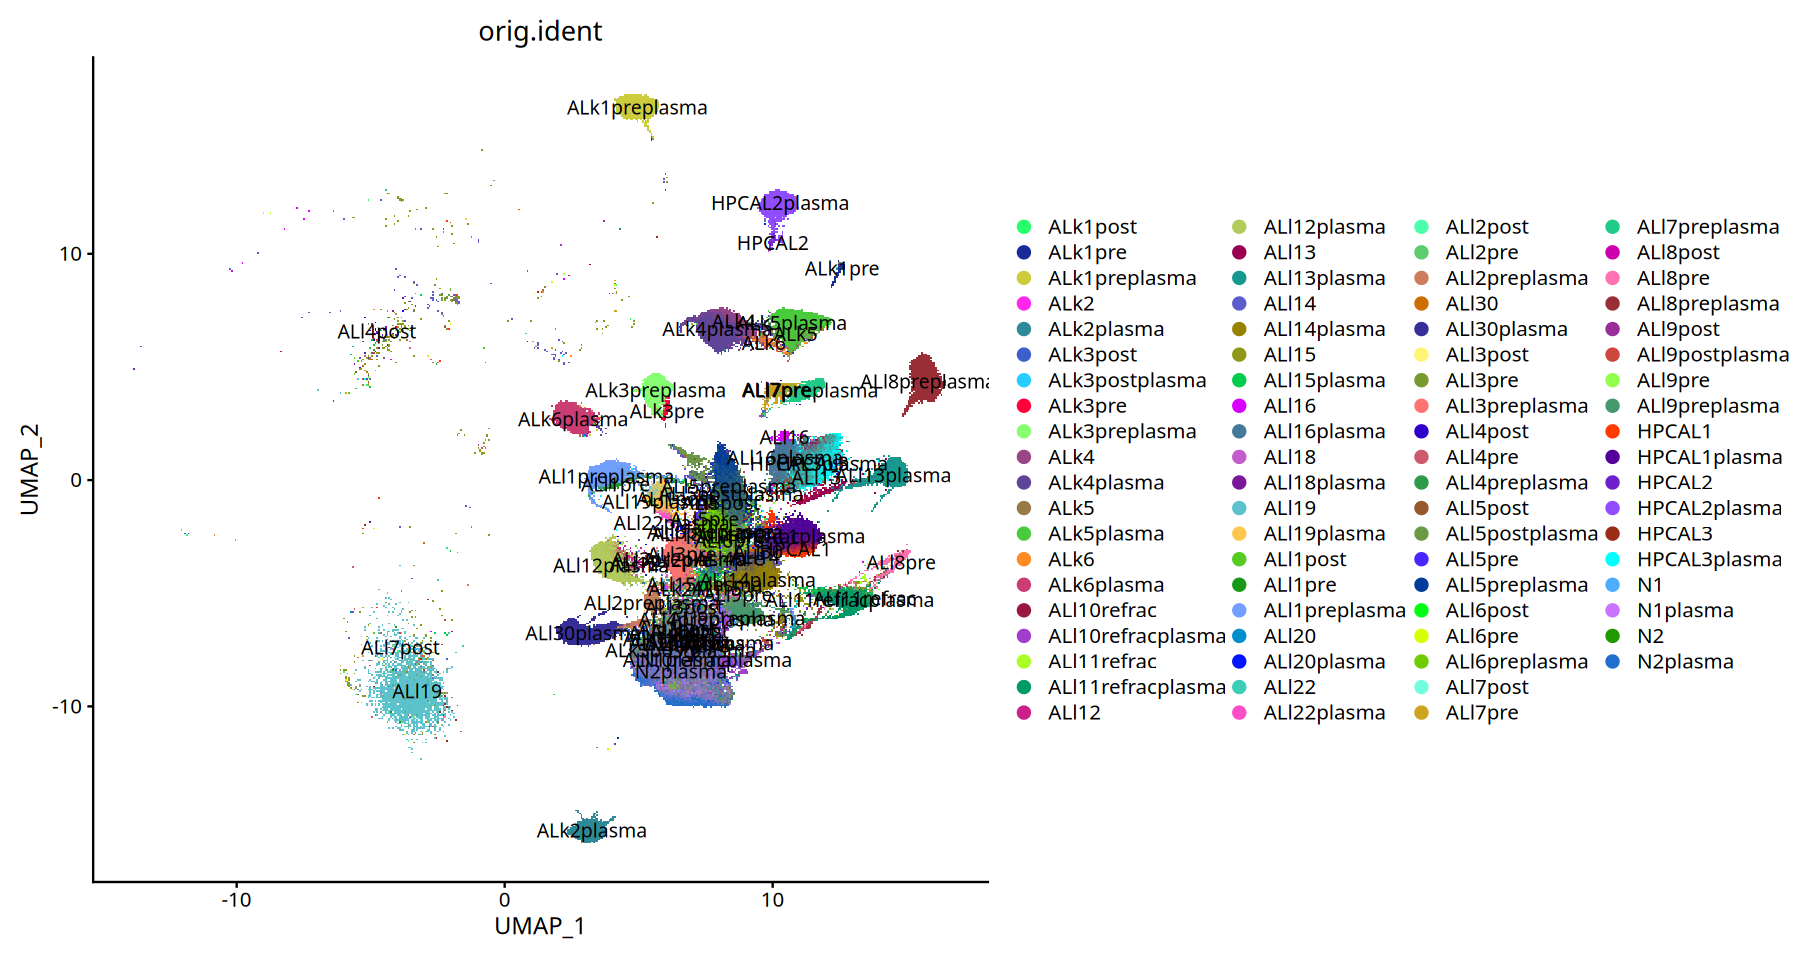

In [5]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=15)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("orig.ident"),label=T) 

## 2. Normalization and dimensional reduction

Normalize plasma-cell expression, remove immunoglobulin genes from the variable-feature set, and calculate principal components.


In [6]:
# Normalize expression and identify variable genes.
sce1_plasma <- NormalizeData(sce1_plasma)
sce1_plasma <- FindVariableFeatures(sce1_plasma)

Normalizing layer: counts

Finding variable features for layer counts



In [7]:
# Step 1: Identify genes starting with "IG"
ig_genes <- grep("^IGK|^IGH|^IGL", rownames(sce1_plasma), value = TRUE)

# Step 2: Exclude these genes from variable features
current_variable_features <- VariableFeatures(sce1_plasma)
filtered_variable_features <- setdiff(current_variable_features, ig_genes)
VariableFeatures(sce1_plasma) <- filtered_variable_features

# Step 3: Proceed with PCA and UMAP
sce1_plasma <- ScaleData(sce1_plasma, features = VariableFeatures(sce1_plasma))
sce1_plasma <- RunPCA(sce1_plasma, features = VariableFeatures(sce1_plasma))

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  RHOB, CITED2, DUSP5, CD79A, QPCT, JSRP1, FCRLA, PELI1, CD9, NFKBIA 
	   CDKN1A, ATF5, FBP1, CAV1, SLC22A17, LMNA, P2RX1, HSPB1, DPEP1, NR4A1 
	   FAM92B, IRF4, BMP6, PHGDH, ABCB9, OTUD1, PTP4A3, CTHRC1, AMPD1, FAM30A 
Negative:  NKG7, GNLY, IL32, FGFBP2, CCL5, PTPRC, GZMA, GZMH, GZMB, CD3D 
	   KLRD1, CST7, HCST, CD2, CD8B, CD3G, FCGR3A, CD52, TRBC2, GIMAP7 
	   CD3E, PRF1, KLRG1, GZMM, PTGDS, CD8A, GIMAP4, LCP1, HLA-DPB1, MYOM2 
PC_ 2 
Positive:  CD99, TMSB4X, SLC22A17, CTSW, CD79A, P2RX1, WFDC2, TMC6, RBP1, CD81 
	   MYADM, SLC22A31, WARS, TNFRSF18, LINC01781, PCSK1N, CD44, TGFBR3L, TCN2, PGLYRP2 
	   ERN1, TIMP1, FAM30A, HLA-DMA, CTHRC1, FCER2, MT1F, TMEM176B, ATF5, ALOX5AP 
Negative:  MT-ND5, PTP4A3, RPS17, NEB, MT-ND2, MT-ND4, NEAT1, MT-CO3, RPL23, HIST1H1C 
	   GAS5, MT-ATP6, CST6, AL353753.1, DHRS9, LINC01088, NUDT12, MT-ND3, TXNIP, HIST

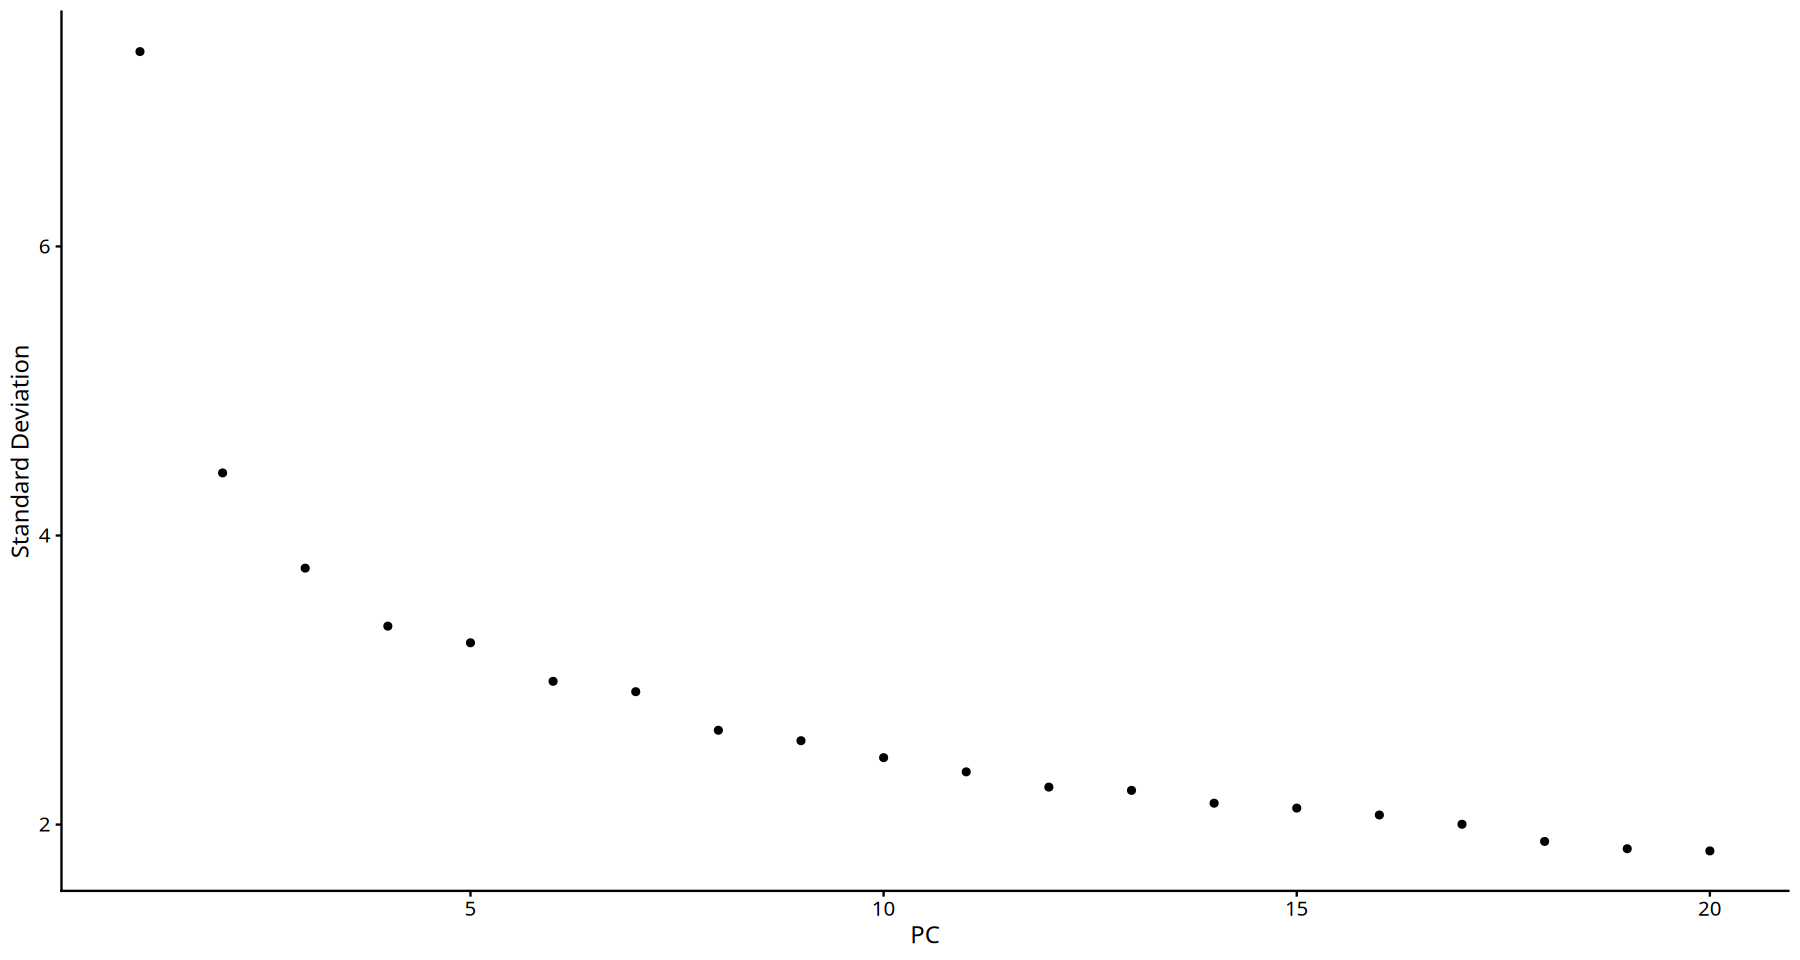

In [8]:
ElbowPlot(sce1_plasma)

## 3. Clustering and UMAP visualization

Construct the neighbor graph, identify plasma-cell clusters, and inspect sample distributions in the UMAP embedding.


In [9]:
# Cluster plasma cells using the first 15 principal components.
sce1_plasma <- FindNeighbors(sce1_plasma, dims = 1:15, reduction = "pca")
sce1_plasma <- FindClusters(sce1_plasma, resolution = 1, cluster.name = "seurat_clusters")

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 232300
Number of edges: 6542590

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9443
Number of communities: 52
Elapsed time: 102 seconds


In [10]:
# Calculate the plasma-cell UMAP embedding.
sce1_plasma <- RunUMAP(sce1_plasma, dims = 1:15, reduction = "pca", reduction.name = "UMAP")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
05:03:22 UMAP embedding parameters a = 0.9922 b = 1.112

05:03:22 Read 232300 rows and found 15 numeric columns

05:03:22 Using Annoy for neighbor search, n_neighbors = 30

05:03:22 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

05:03:48 Writing NN index file to temp file /tmp/RtmpZijR8z/file2900e74ef3062

05:03:48 Searching Annoy index using 1 thread, search_k = 3000

05:05:33 Annoy recall = 100%

05:05:34 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbor

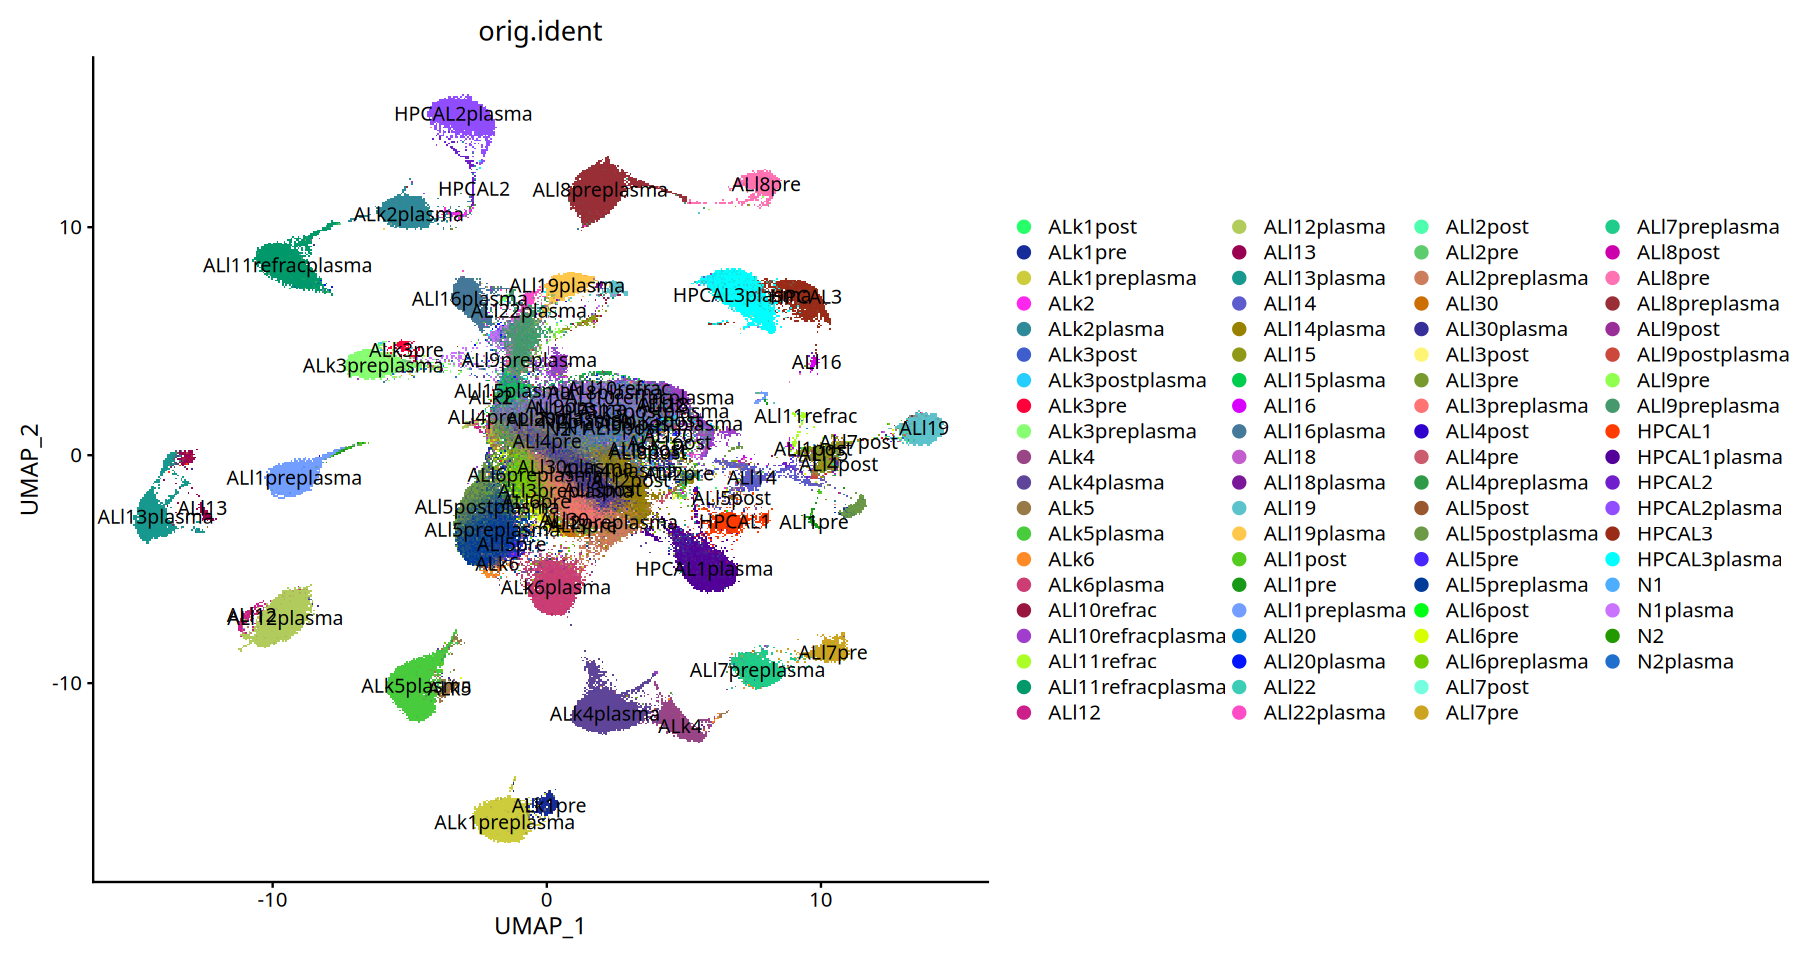

In [11]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=15)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("orig.ident"),label=T) 

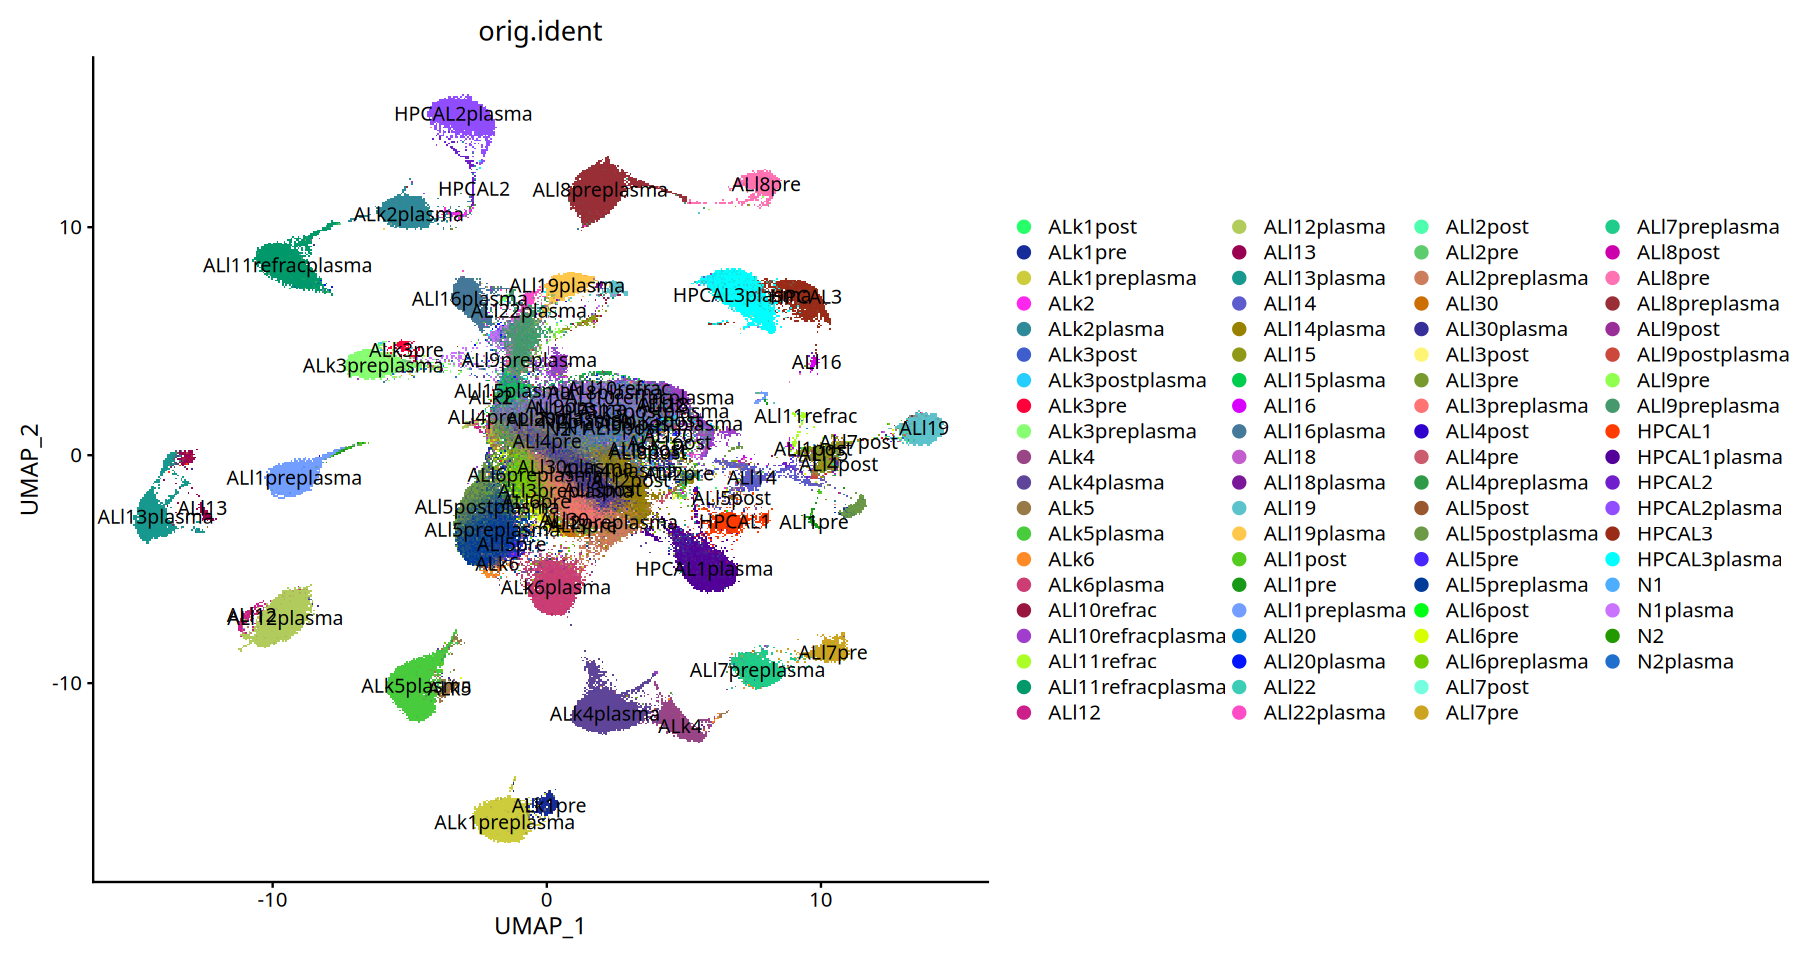

In [12]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=15)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("orig.ident"),label=T) 


NOTE: DimPlot_scCustom returns split plots as layout of all plots each
with their own axes as opposed to Seurat which returns with shared x or y axis.
To return to Seurat behvaior set `split_seurat = TRUE`.

-----This message will be shown once per session.-----


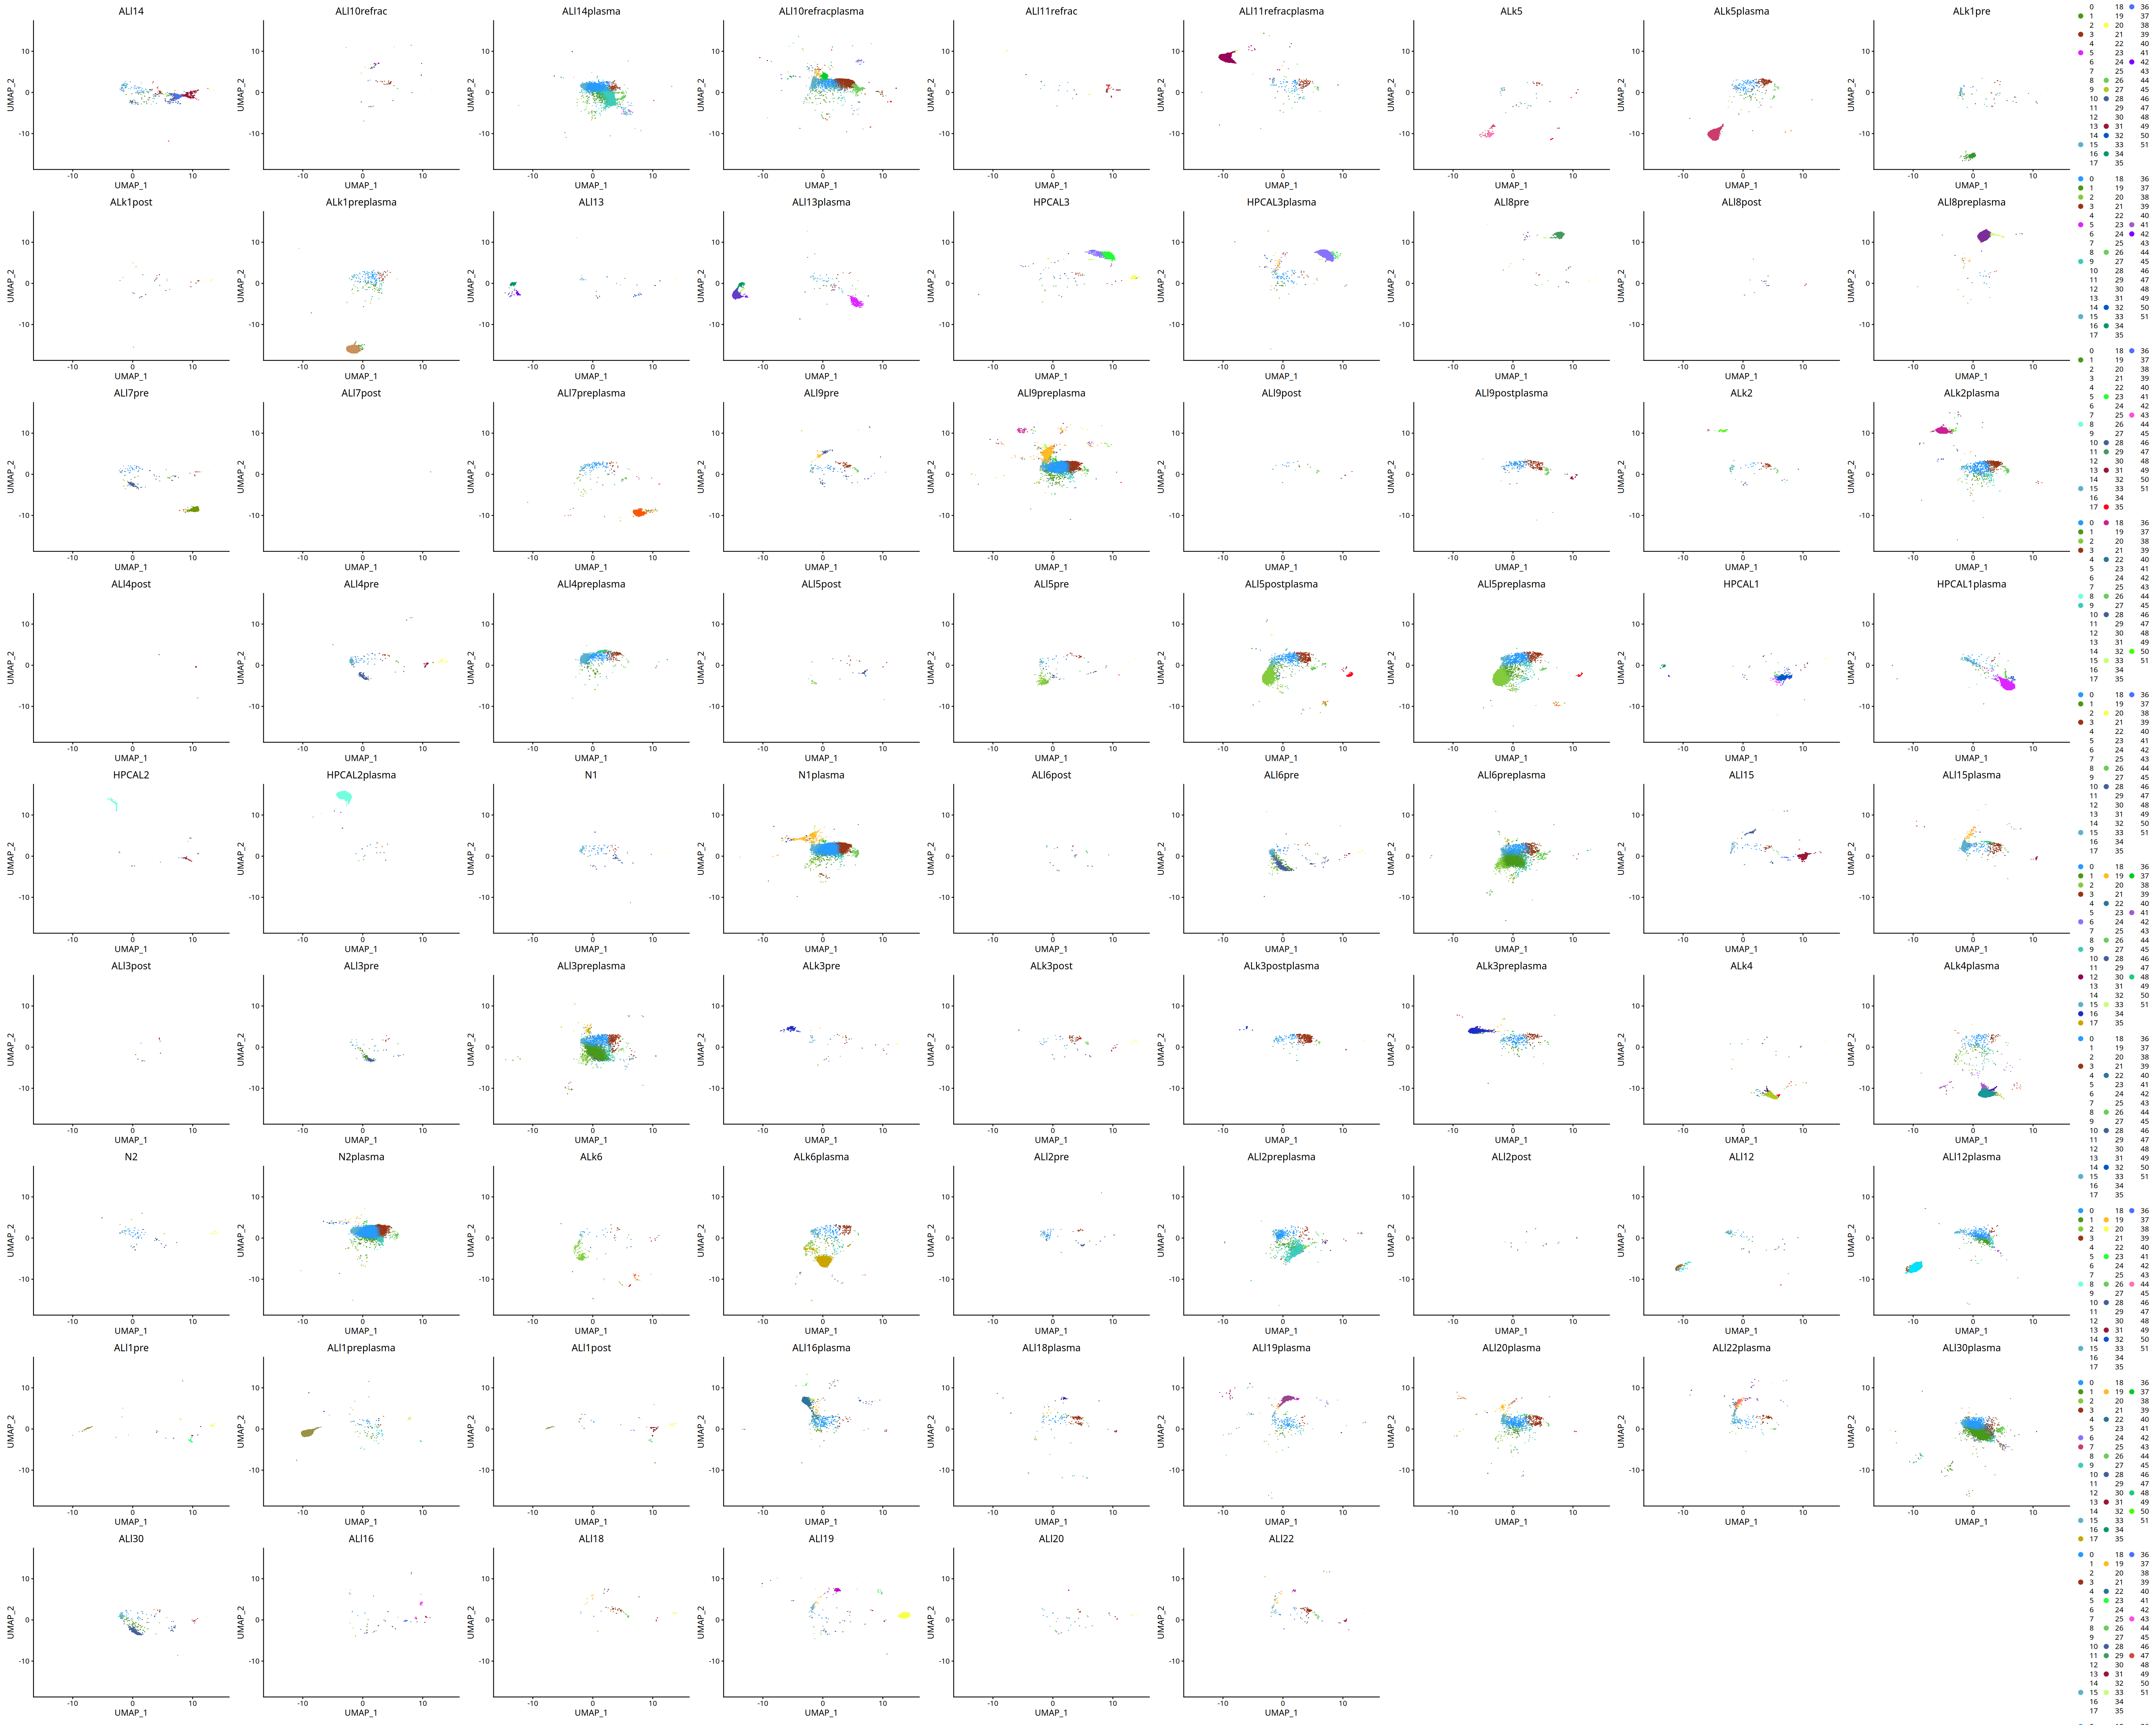

In [13]:
library(scCustomize)
options(repr.plot.height=40,repr.plot.width=50)
DimPlot_scCustom(sce1_plasma, pt.size=2,reduction = "UMAP", split.by = c("orig.ident"),label=F) 

## 4. Cluster review and sample identifiers

Review plasma-cell clusters and initialize sample-derived metadata.


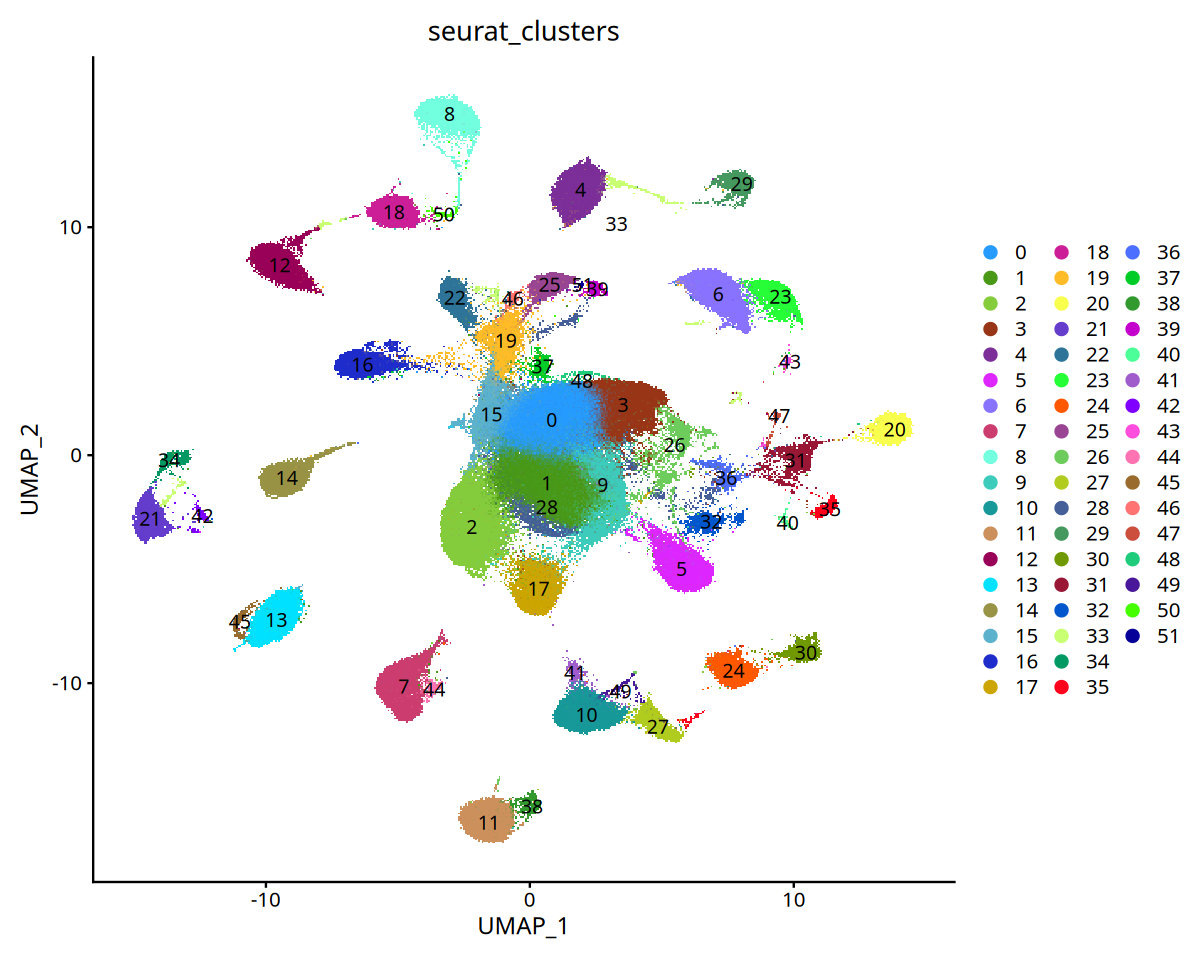

In [14]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=10)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("seurat_clusters"),label=T) 

In [15]:
sce1_plasma

An object of class Seurat 
36601 features across 232300 samples within 1 assay 
Active assay: RNA (36601 features, 1755 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, UMAP

In [16]:
# Initialize disease-subtype labels from the original sample identifiers.
sce1_plasma@meta.data$subtype<-sce1_plasma@meta.data$orig.ident

## 5. Disease subtype and cytogenetic annotations

Harmonize disease-subtype labels and carry baseline cytogenetic annotations into the corresponding treatment samples.


In [17]:
# Harmonize sample-derived disease-subtype labels.
sce1_plasma@meta.data$subtype<-gsub('HPCAL1','HPCAL',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('HPCAL2','HPCAL',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('HPCAL3','HPCAL',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('HPCALplasma','HPCAL',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('N1','N',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('N2','N',sce1_plasma@meta.data$subtype)
sce1_plasma@meta.data$subtype<-gsub('Nplasma','N',sce1_plasma@meta.data$subtype)

In [18]:
# Retain the three-character disease-subtype code.
sce1_plasma@meta.data$subtype <- substr(sce1_plasma@meta.data$subtype, 1, 3)

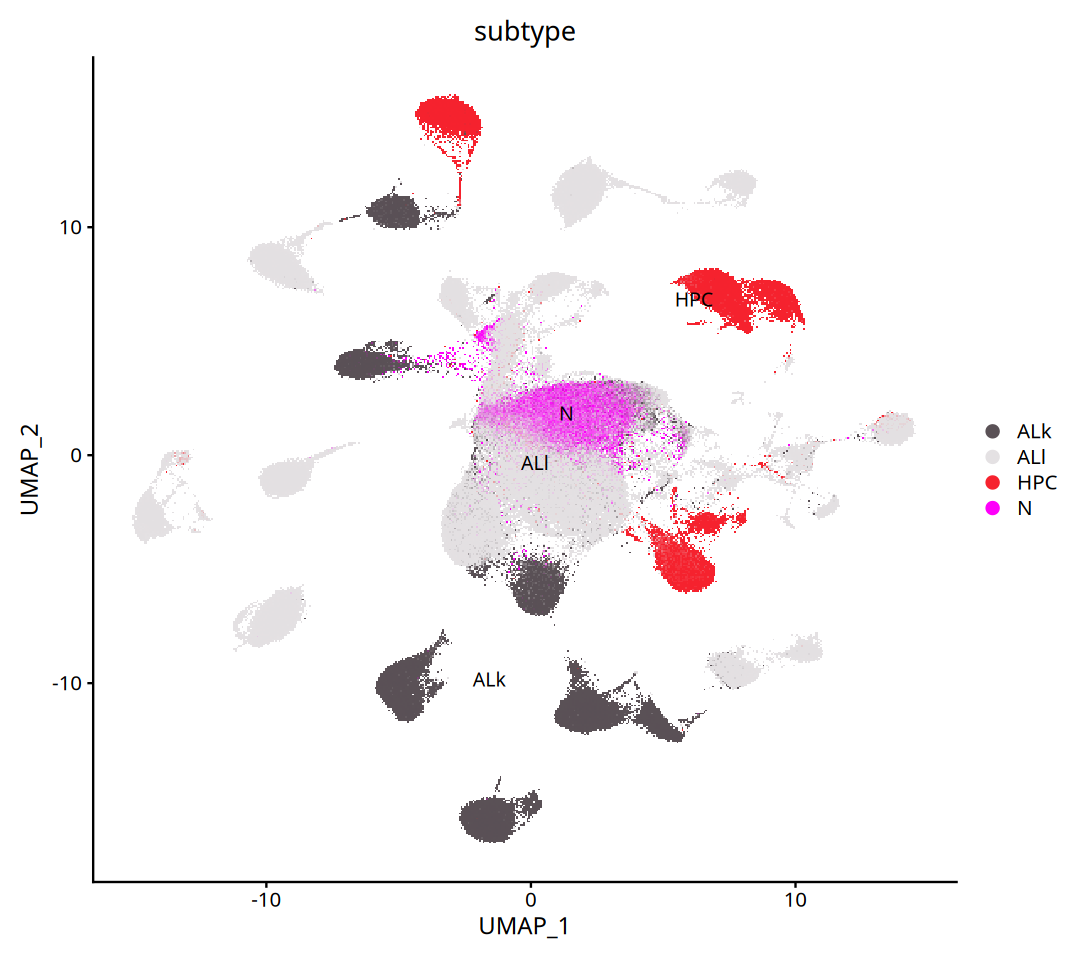

In [19]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=9)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("subtype"),label=T,order=T) 

In [20]:
# Carry baseline cytogenetic annotations into the corresponding treatment samples.
sce1_plasma@meta.data$mutation<-sce1_plasma@meta.data$orig.ident
sce1_plasma@meta.data$mutation<-gsub('ALl10refracplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl10refrac','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl11refracplasma','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl11refrac','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk4plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk4','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk5plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk5','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk2plasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk2','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk6plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk6','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk1preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk1pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk1postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk1post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk3preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk3pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk3postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALk3post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl1preplasma','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl1pre','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl1postplasma','1q21(gain)_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl1post','1q21(gain)_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl2preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl2pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl2postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl2post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl3preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl3pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl3postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl3post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl5preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl5pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl5postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl5post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl7preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl7pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl7postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl7post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl8preplasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl8pre','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl8postplasma','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl8post','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl9preplasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl9pre','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl9postplasma','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl9post','None_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl4preplasma','NA',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl4pre','NA',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl4postplasma','NA',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl4post','NA',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl6preplasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl6pre','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl6postplasma','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl6post','IgH/CCND1(t(11;14))_Post',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl12plasma','IgH/FGFR3(t(4;14))/1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl12','IgH/FGFR3(t(4;14))/1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl13plasma','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl13','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl14plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl14','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl15plasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl15','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl16plasma','17p13.1(del)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl16','17p13.1(del)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl18plasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl18','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl19plasma','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl19','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl20plasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl20','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl22plasma','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl22','None_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL1plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL1','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl30plasma','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('ALl30','IgH/CCND1(t(11;14))_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL2plasma','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL2','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL3plasma','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('HPCAL3','1q21(gain)_Pre',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('N1plasma','Normal',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('N1','Normal',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('N2plasma','Normal',sce1_plasma@meta.data$mutation)
sce1_plasma@meta.data$mutation<-gsub('N2','Normal',sce1_plasma@meta.data$mutation)

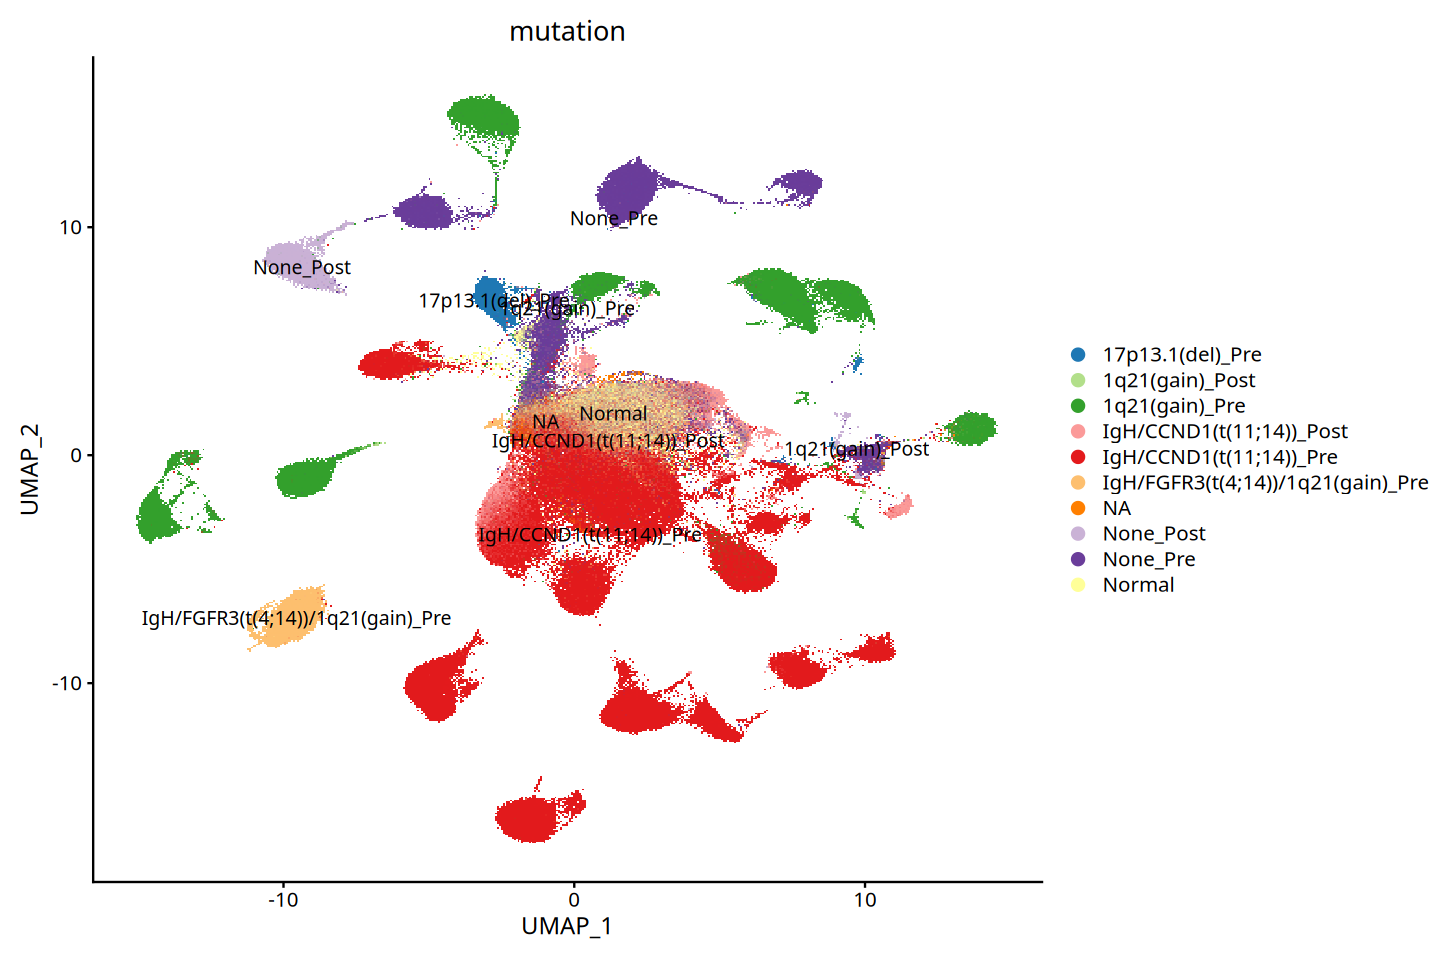

In [21]:
library(scCustomize)
options(repr.plot.height=8,repr.plot.width=12)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("mutation"),label=T,order=T, colors_use = RColorBrewer::brewer.pal(n = 11, name = "Paired")[2:11])

## 6. Sample labels and metadata preparation

Inspect cytogenetic annotations by sample and prepare cluster and sample identifiers for program-level summaries.


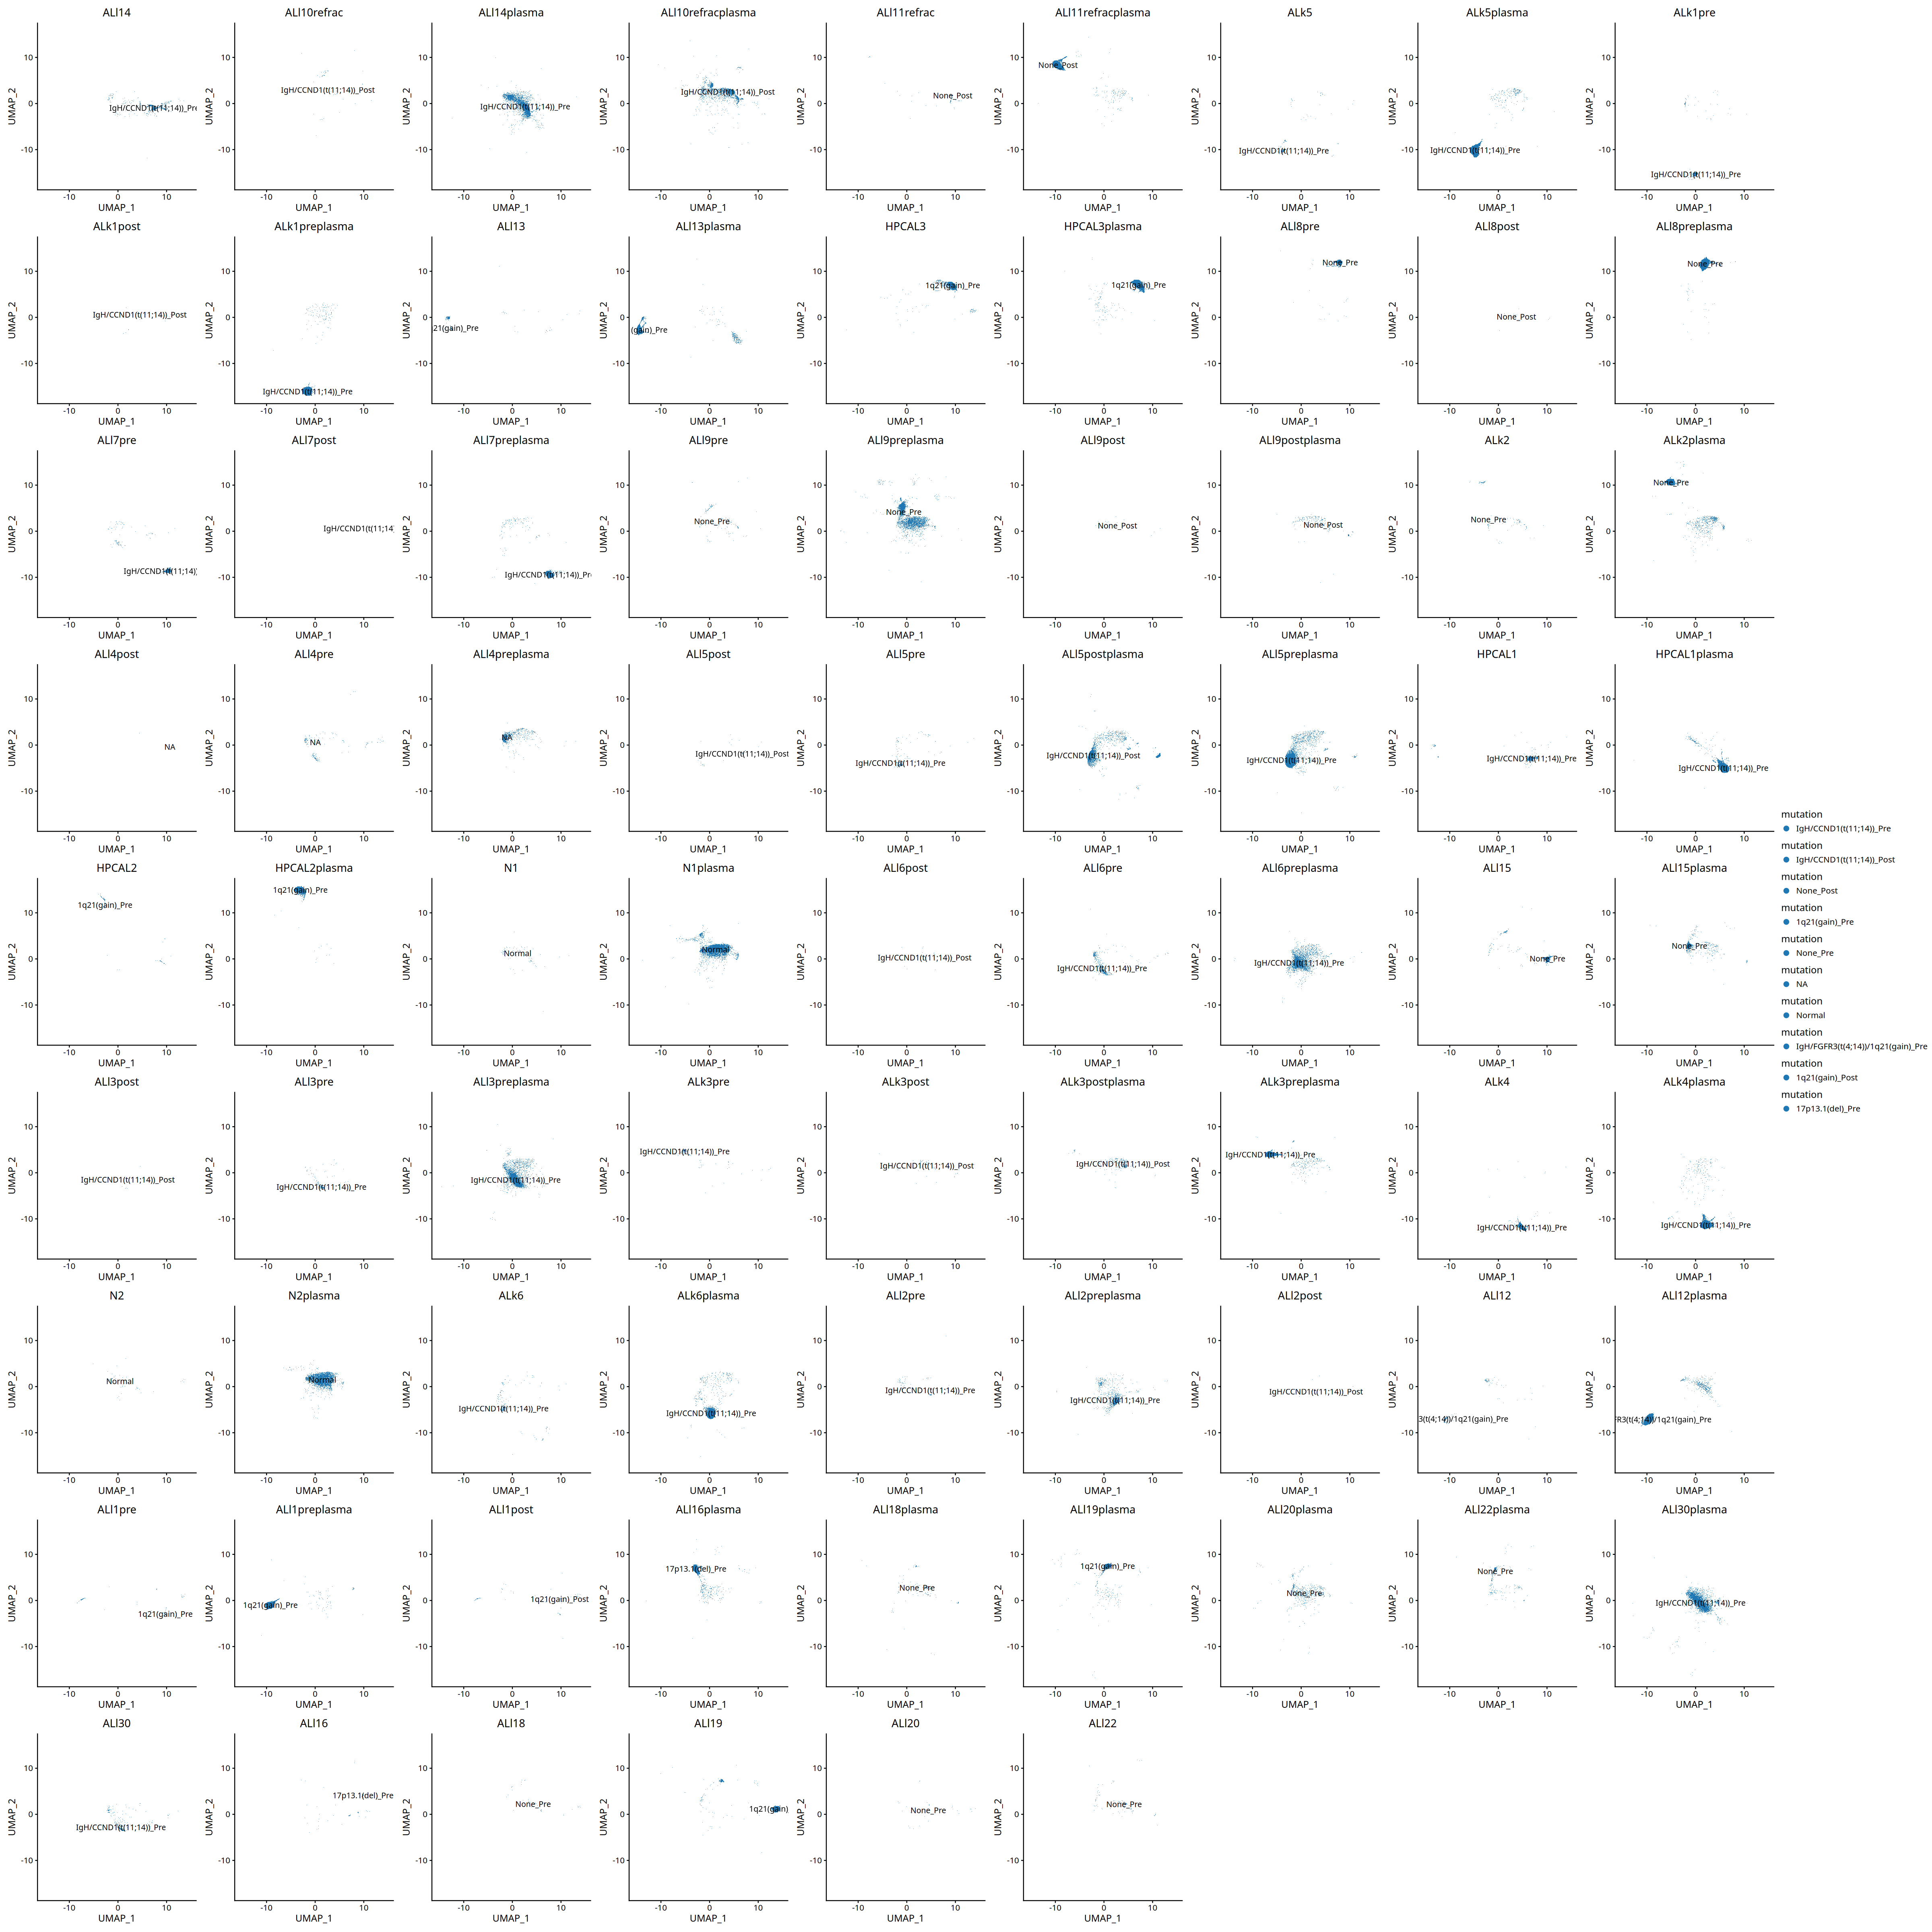

In [22]:
# Inspect cytogenetic annotations separately for each sample.
library(scCustomize)
options(repr.plot.height=40,repr.plot.width=40)
DimPlot_scCustom(sce1_plasma, pt.size=1,reduction = "UMAP", group.by = c("mutation"),split.by='orig.ident',label=T,order=T, colors_use = RColorBrewer::brewer.pal(n = 11, name = "Paired")[2:11])

In [23]:
# Report the number of excluded immunoglobulin genes.
length(ig_genes)

[1] 411

In [24]:
# Add a readable prefix to the plasma-cell cluster identifiers.
sce1_plasma@meta.data$"seurat_clusters"<-paste('cluster',sce1_plasma@meta.data$"seurat_clusters",sep='')

## 7. Import starCAT program usages

Import the cell-by-program usage table exported by [2.3_starCAT_plasmacellsGEP.ipynb](2.3_starCAT_plasmacellsGEP.ipynb) and align rows to Seurat cell barcodes. The historical `cnmf` filename refers to the cNMF-derived reference programs; the query usages are produced by starCAT.


In [25]:
# Retain sample identifiers for sample-level starCAT usage summaries.
sce1_plasma@meta.data$"sample_id"<-sce1_plasma@meta.data$"orig.ident"

In [26]:
sce1_plasma

An object of class Seurat 
36601 features across 232300 samples within 1 assay 
Active assay: RNA (36601 features, 1755 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, UMAP

In [27]:
# Read starCAT usages exported by notebook 2.3 (historical cNMF reference filename).
GEP<-read.csv('plasma_cnmf_3_usage_norm_withoutIG_k=13_allplasmacell.csv')

In [28]:
# Use the exported cell barcodes as the usage-table row names.
rownames(GEP)<-GEP$X
GEP$X<-NULL

In [29]:
# Align starCAT usages to Seurat metadata by cell barcode before joining.
sce1_plasma@meta.data<-cbind(sce1_plasma@meta.data,GEP[rownames(sce1_plasma@meta.data),])

## 8. Sample-level program summaries

Calculate the mean starCAT usage of each selected GEP within each sample and display the sample-level program heatmap.


In [30]:
# Remove redundant identifiers after retaining sample_id.
sce1_plasma@meta.data$barcode<-NULL
sce1_plasma@meta.data$orig.ident<-NULL

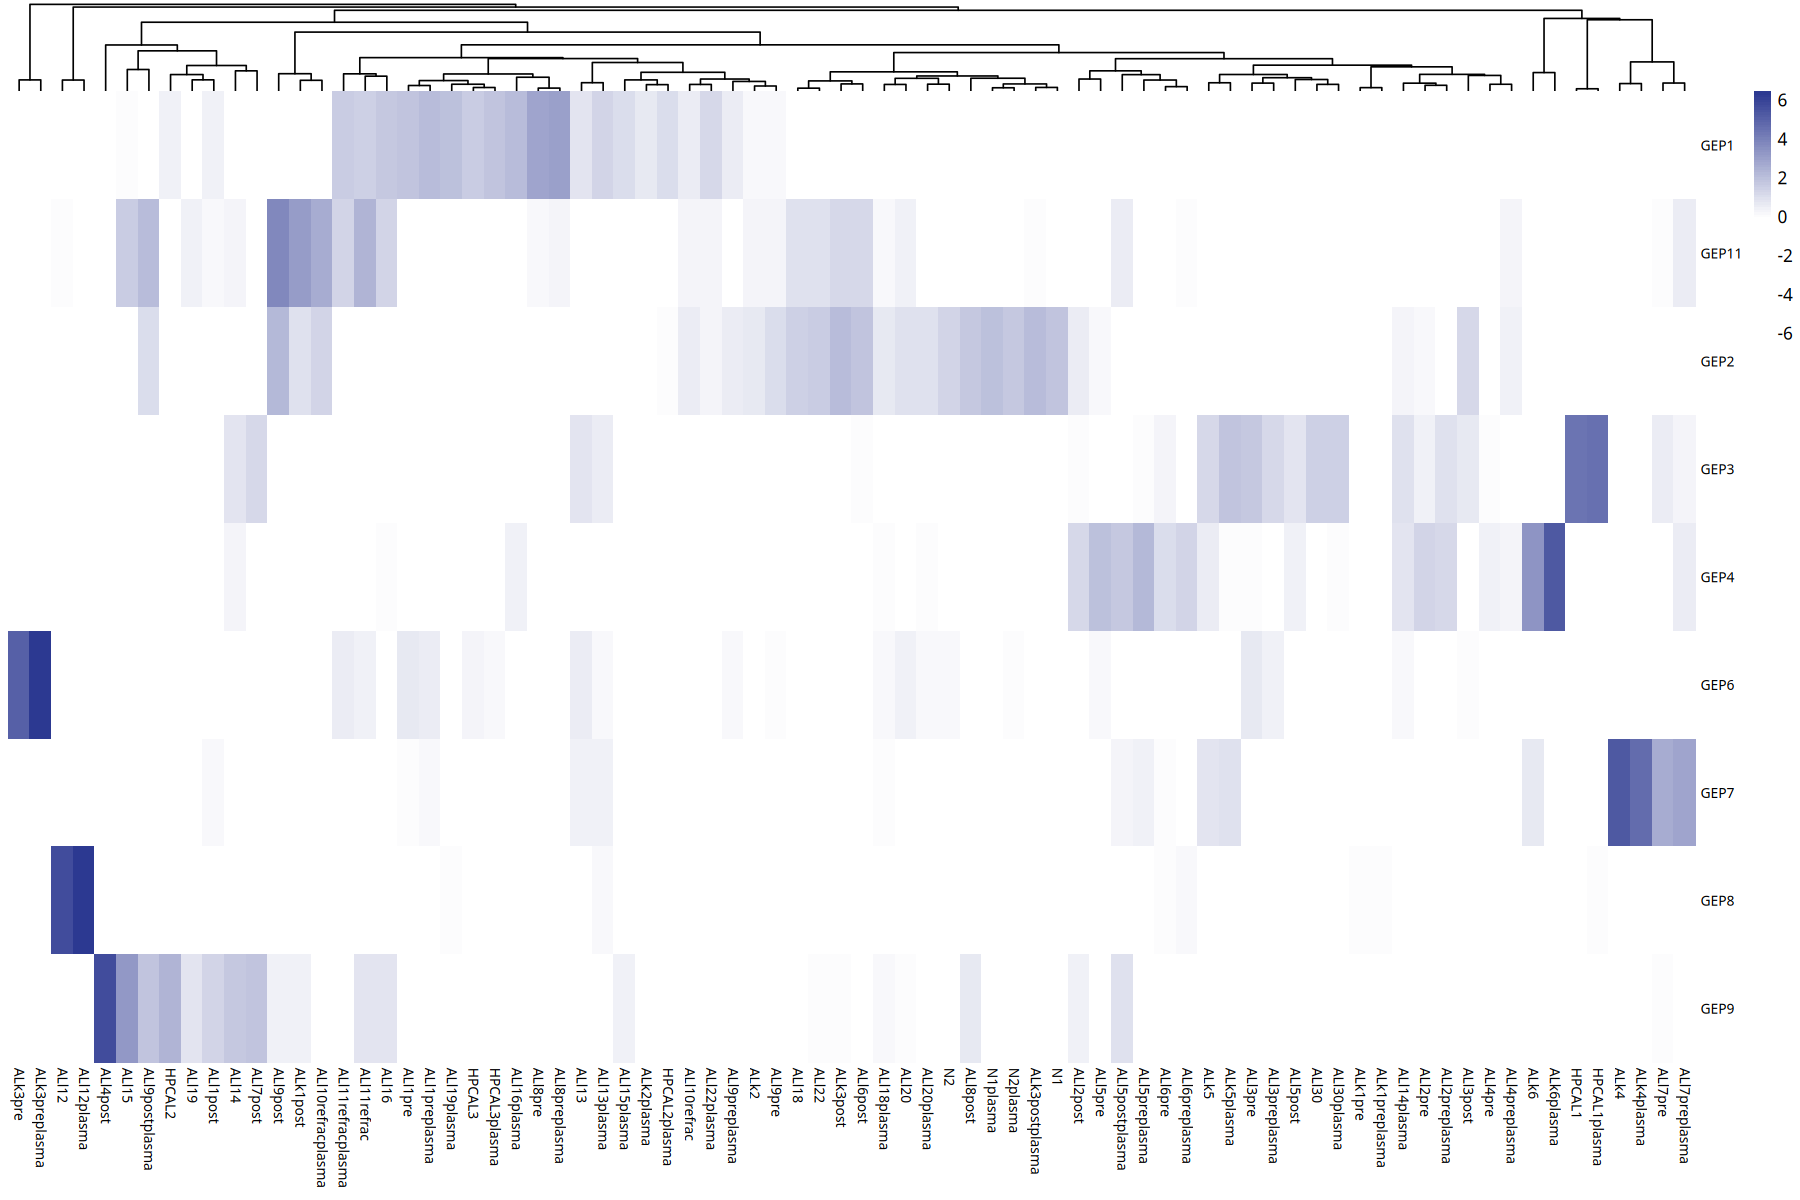

In [35]:
library(tibble)
library(dplyr)
library(pheatmap)

options(repr.plot.height=10,repr.plot.width=15)

# 1. Extract metadata
meta <- sce1_plasma@meta.data

# 2. Define the features and the group
features <- c('GEP1','GEP11','GEP2','GEP3','GEP4','GEP6','GEP7','GEP8','GEP9')

# 3. Calculate mean starCAT usage per sample
avg_mat <- meta %>%
  group_by(sample_id) %>%
  summarise(across(all_of(features), mean, na.rm = TRUE)) %>%
  column_to_rownames("sample_id") %>%
  t()  # Programs as rows and sample identifiers as columns.

# 4. Plot the heatmap
pheatmap(avg_mat,
         scale = "row",  # Standardize each program across samples.
  border = FALSE,
  cluster_rows = FALSE,
  clustering_distance_cols = "euclidean",
  clustering_method = "complete",
  color = colorRampPalette(c("white", "white", "#2c3991"))(100),
  fontsize_row = 8,  # Program-label font size.
  fontsize_col = 8,
  show_rownames = TRUE,
  show_colnames = TRUE)

## 9. Clinical annotations and response groups

Match clinical annotations to the sample-level usage matrix using the longest case-insensitive sample-name prefix. Build `boxplot` from the same matrix and annotations. Response labels combine CR/VGPR (Good) or PR/NR/SD (Poor) with the treatment timepoint; sample names containing `post` or `refrac` indicate post-treatment samples.


In [36]:
# Initial prefix-match annotation preview; the next cell refines ambiguous matches.
library('RColorBrewer')

# 1. Read the CSV
sample_info <- read.csv("./sampleannotation-all.csv", stringsAsFactors = FALSE)
# 3. For each column in the CSV, match to heatmap columns
# We'll build a big annotation data.frame
annotation_list <- lapply(sample_info, function(info_column) {
  sapply(colnames(avg_mat), function(col) {
    matched <- sapply(sample_info$samplename, function(samplename) {
      grepl(paste0("^", samplename), col)
    })
    if (any(matched)) {
      info_column[which(matched)[1]]  # pick the first match
    } else {
      NA
    }
  })
})

# 4. Convert annotation_list to a data.frame
annotation_df <- as.data.frame(annotation_list)
rownames(annotation_df) <- colnames(avg_mat)
annotation_df$samplename<-NULL

# 5. Add your original Group and Sample annotations
annotation_col <- annotation_df

# 6. Generate colors for each annotation automatically
# (you can customize this part further if you want fancy colors)
ann_colors <- list()
# Get Set1 palette with up to 9 colors
my_colors <- brewer.pal(9, "Spectral")
for (colname in colnames(annotation_col)) {
  values <- unique(na.omit(annotation_col[[colname]]))
  if (length(values) <= 10) { # if <=10 unique groups, assign distinct colors
    ann_colors[[colname]] <- setNames(
      colorRampPalette(my_colors)(length(values)),
      values
    )
  }
}


In [ ]:
library(RColorBrewer)

# 1. Read clinical annotations required for sample-level response comparisons.
sample_info <- read.csv("./sampleannotation-all.csv", stringsAsFactors = FALSE)
stopifnot(all(c("samplename", "bestorlast.response", "mut") %in% names(sample_info)))

# Case-insensitive "starts with"
starts_with_ci <- function(x, prefix) {
  startsWith(tolower(x), tolower(prefix))
}

# 2. Match sample identifiers case-insensitively; the longest prefix wins.
annotation_list <- lapply(sample_info, function(info_column) {
  sapply(colnames(avg_mat), function(col) {
    # which sample names are prefixes of this heatmap column?
    matched <- vapply(sample_info$samplename,
                      function(sn) starts_with_ci(col, sn),
                      logical(1))
    if (!any(matched)) return(NA)

    idxs <- which(matched)
    # choose the longest samplename among the matches
    lens <- nchar(sample_info$samplename[idxs], type = "chars", allowNA = FALSE, keepNA = FALSE)
    idx  <- idxs[ which.max(lens) ]
    info_column[idx]
  })
})

# 3. Align clinical annotations to the sample-level usage matrix.
annotation_df <- as.data.frame(annotation_list, stringsAsFactors = FALSE)
rownames(annotation_df) <- colnames(avg_mat)
annotation_df$samplename <- NULL
annotation_col <- annotation_df

# 4. Assign colors to the clinical annotation categories.
ann_colors <- list()
base_pal <- brewer.pal(9, "Spectral")
for (colname in colnames(annotation_col)) {
  vals <- unique(na.omit(annotation_col[[colname]]))
  if (length(vals) > 0) {
    ann_colors[[colname]] <- setNames(colorRampPalette(base_pal)(length(vals)), vals)
  }
}



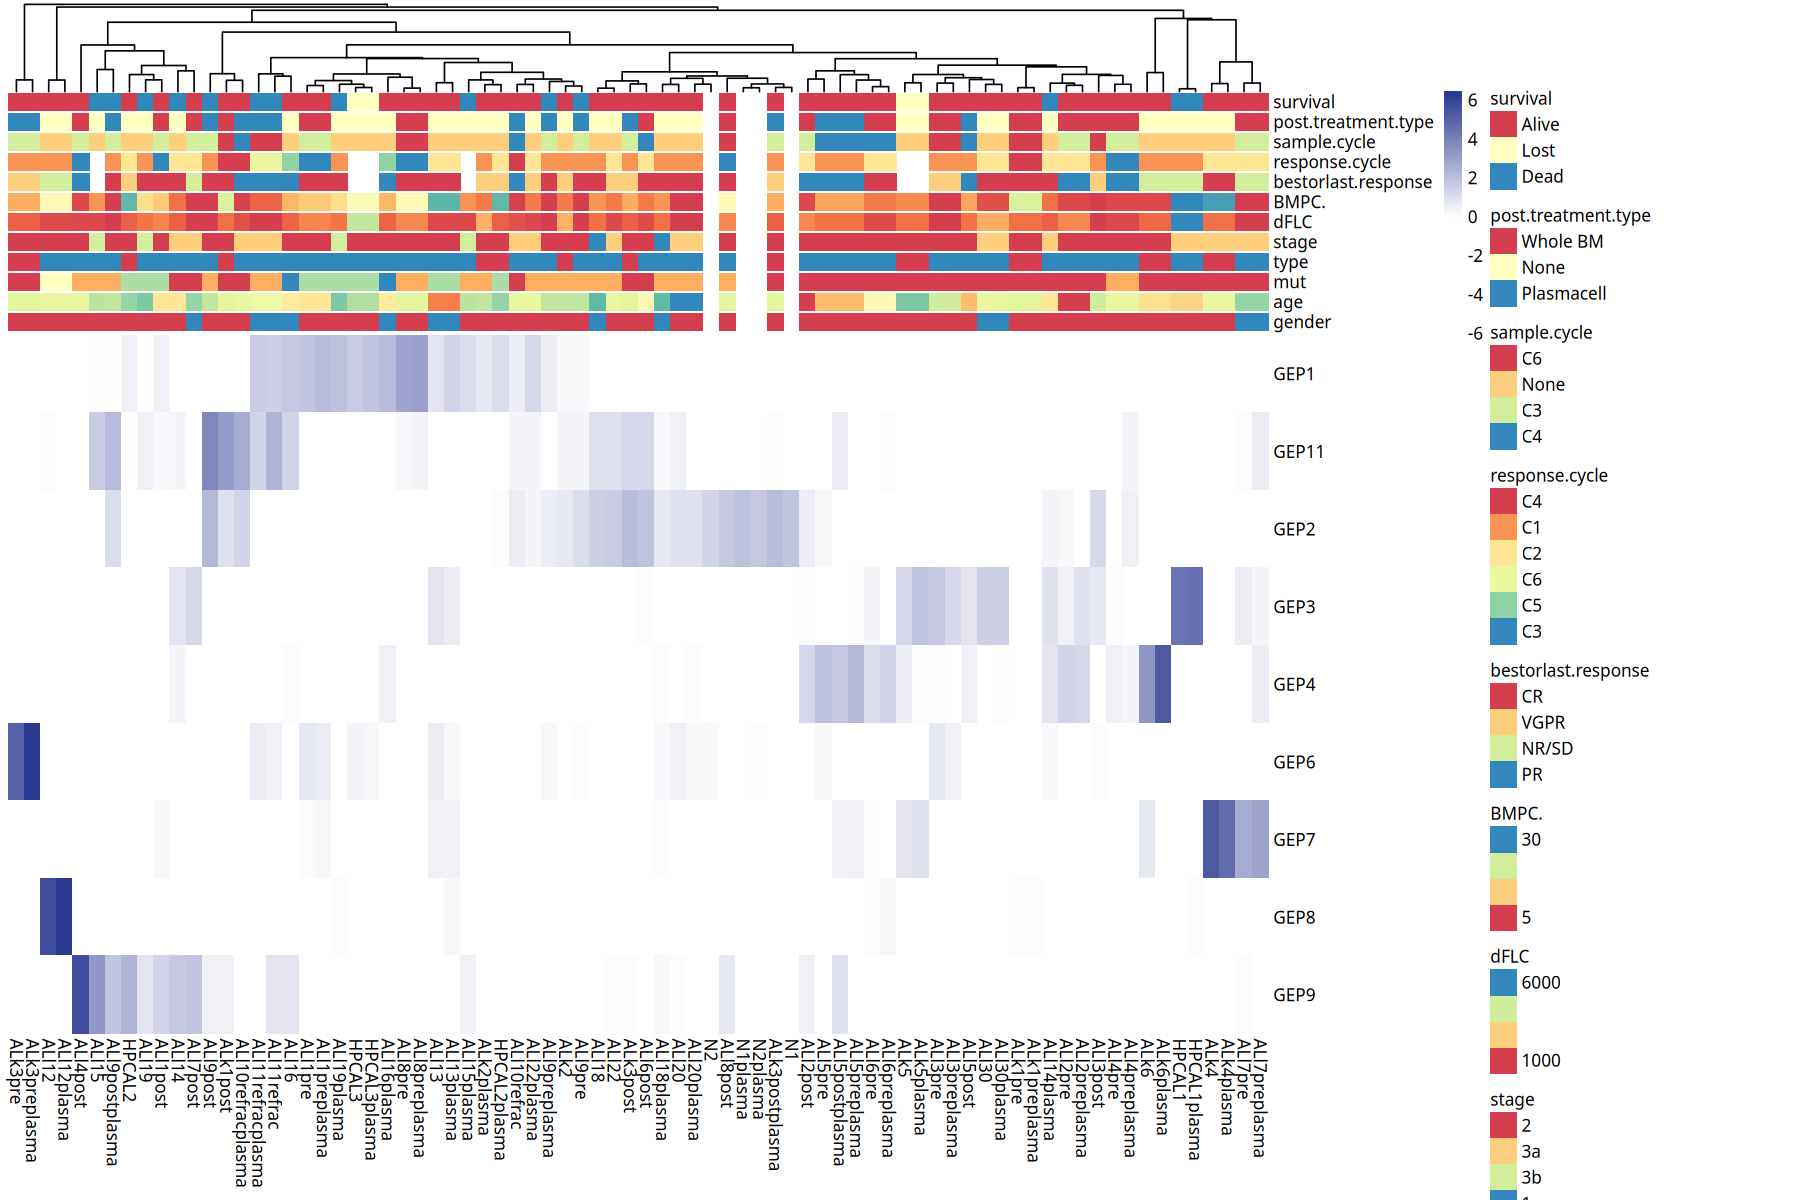

In [38]:
# 7. Plot the heatmap

options(repr.plot.height = 10, repr.plot.width = 15)
pheatmap(avg_mat,
         scale = "row",  # Standardize each program across samples.
  border = FALSE,
  cluster_rows = FALSE,
  clustering_distance_cols = "euclidean",
  clustering_method = "complete",
  color = colorRampPalette(c("white", "white", "#2c3991"))(100),
  fontsize_row = 10,  # Program-label font size.
  fontsize_col = 10,
  show_rownames = TRUE,
  show_colnames = TRUE,
  annotation_col = annotation_col,
  annotation_colors = ann_colors
)


In [ ]:
# Build the sample-level starCAT usage and clinical-response table.
boxplot<-as.data.frame(t(avg_mat))
boxplot<-cbind(boxplot,annotation_col[rownames(boxplot),])
boxplot<-boxplot[!is.na(boxplot$bestorlast.response), ]

# Tag bestorlast.response based on row names
boxplot$bestorlast.response.tag <- ifelse(
  grepl("post|refrac", rownames(boxplot), ignore.case = TRUE),
  "post",
  "pre"
)
boxplot$response<-paste(boxplot$bestorlast.response	,boxplot$bestorlast.response.tag,sep="_")

# Add response group and treatment
boxplot$group2 <- ifelse(boxplot$response %in% c("CR_pre", "VGPR_pre", "CR_post", "VGPR_post"), "Good", "Poor")
boxplot$treatment <- ifelse(grepl("_pre", boxplot$response), "Pre", 
                            ifelse(grepl("_post", boxplot$response), "Post", NA))


## 10. Program usages by response and cytogenetic subgroup

Plot pretreatment Good versus Poor (B), post-treatment Good versus Poor (C), and pre- versus post-treatment distributions within each response group (D). Tests are unpaired Wilcoxon comparisons of sample-level starCAT usages and require at least three samples per comparison arm. Display nominal p-values and, where available, Cliff's delta; these exploratory p-values are not adjusted for multiple testing. This inline section uses GEP1, GEP11, GEP2, GEP3, GEP4, GEP6, GEP7, GEP8, and GEP9.


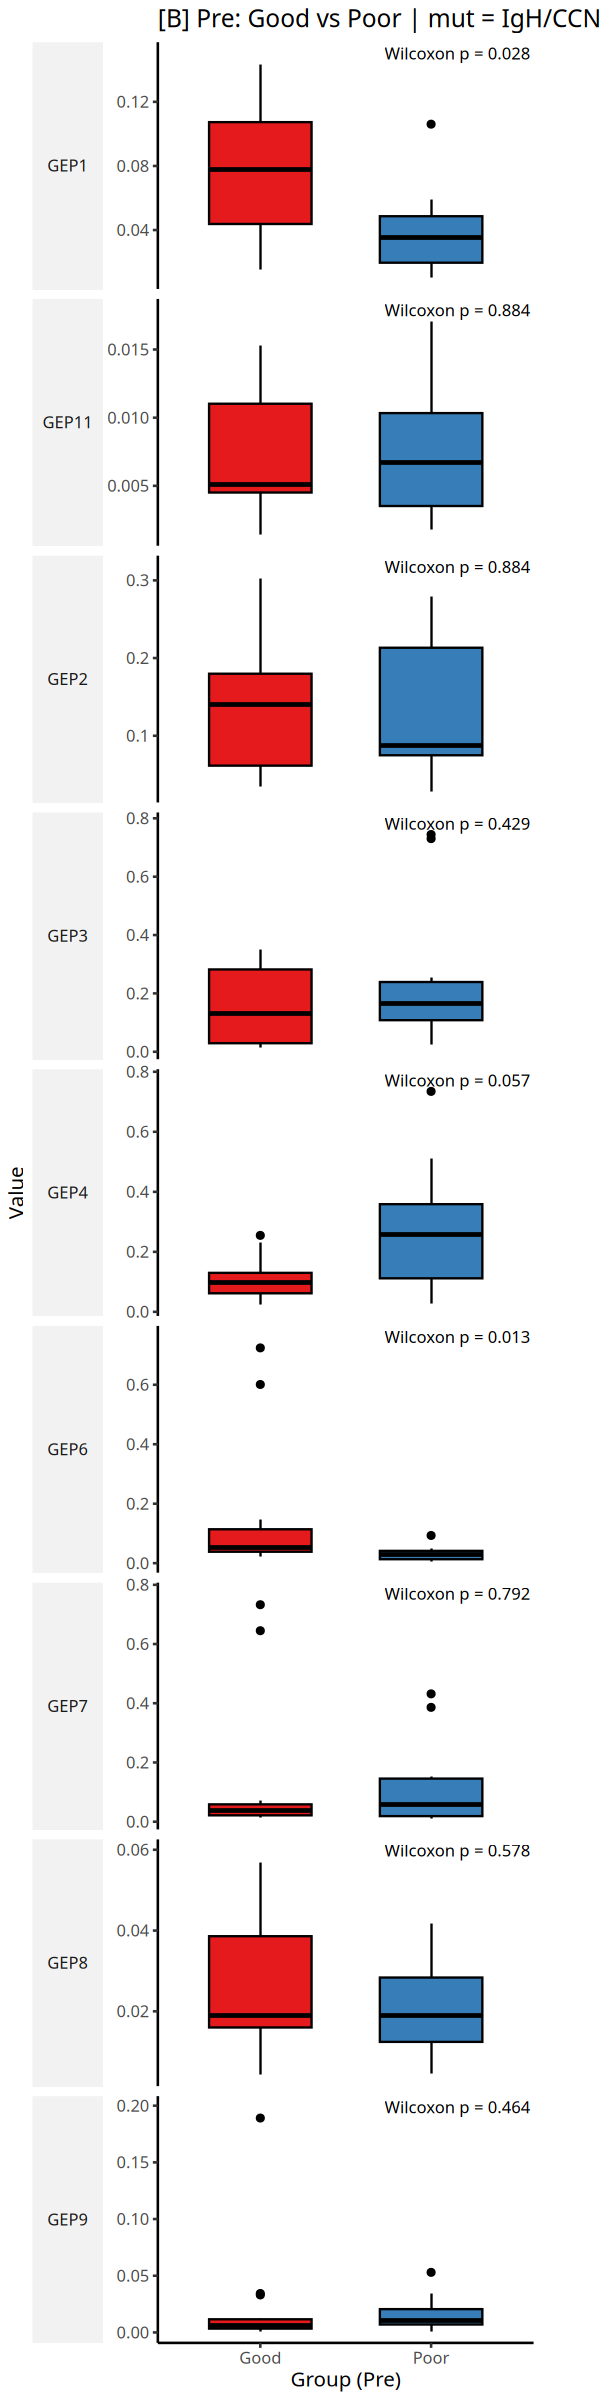

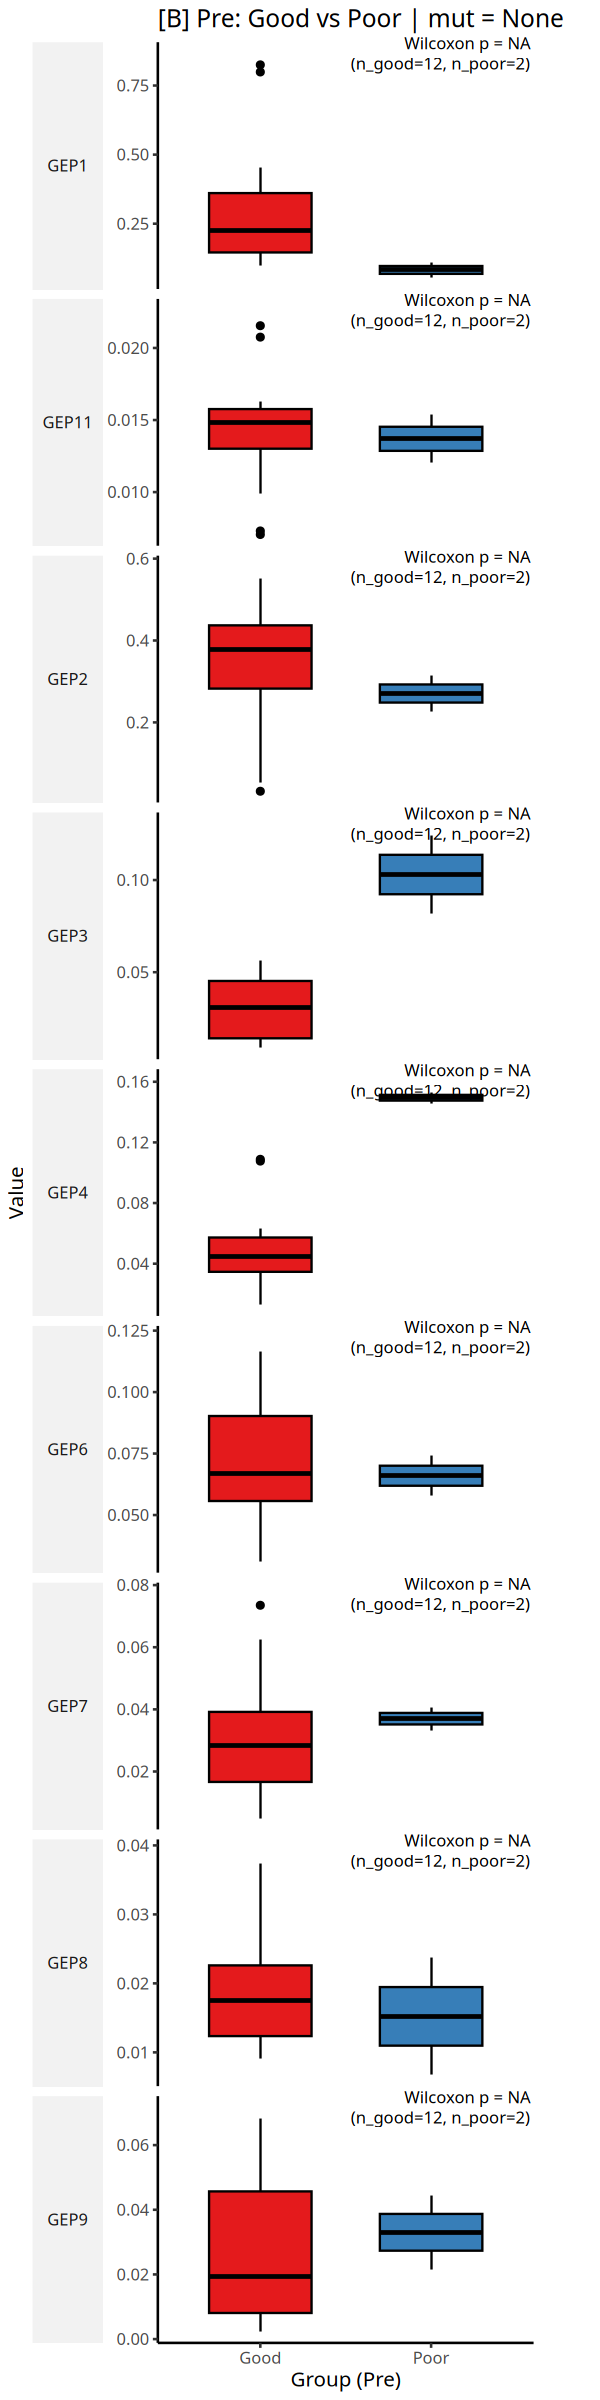

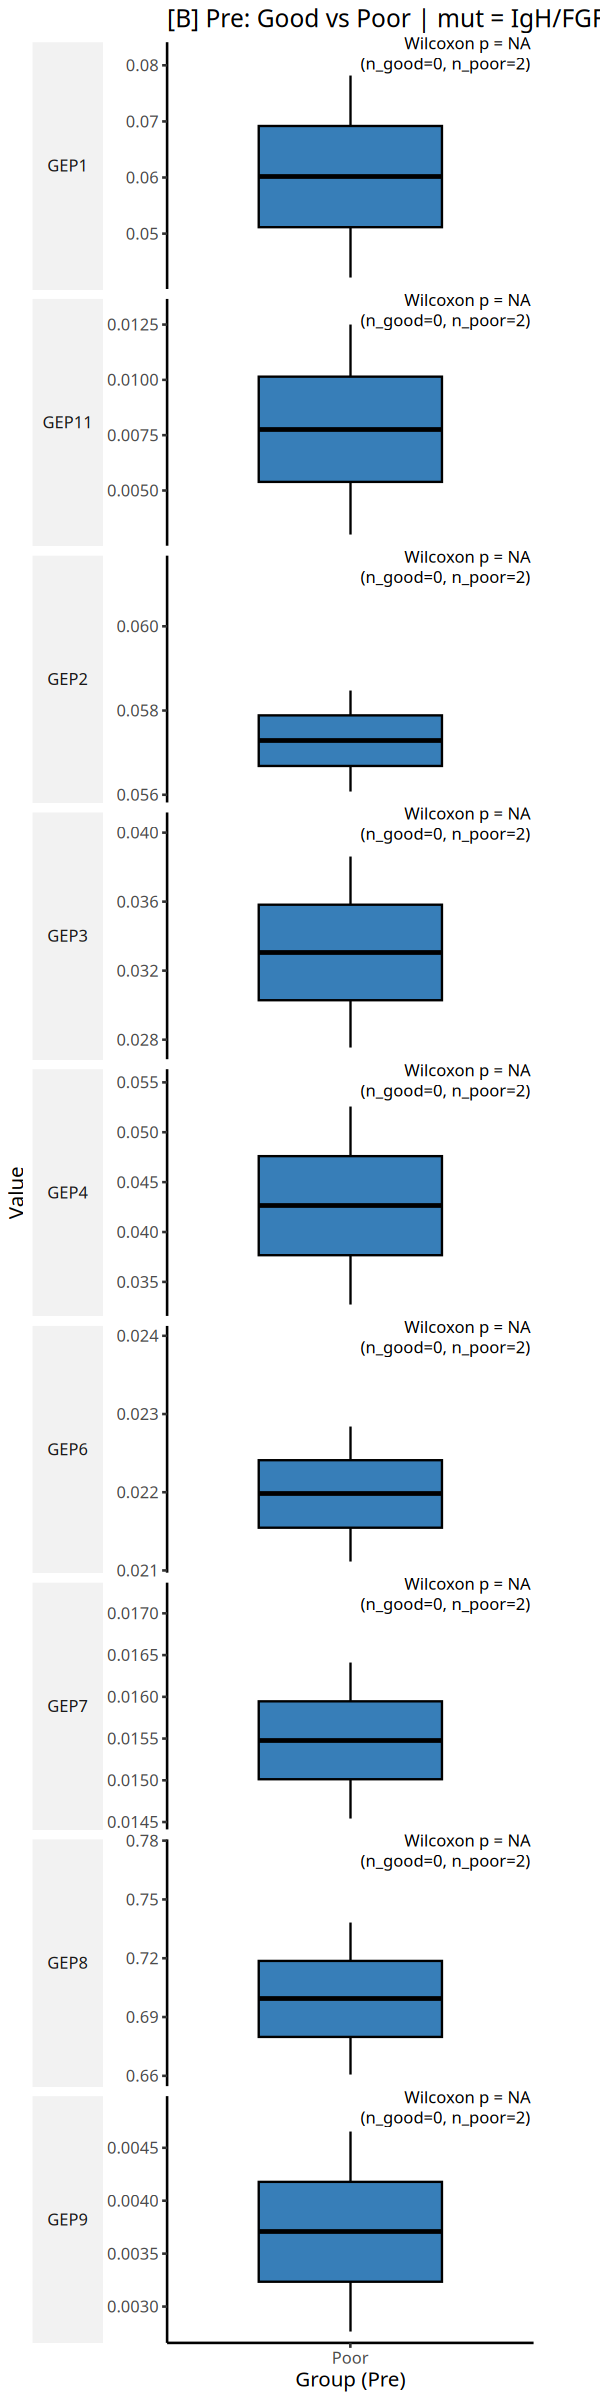

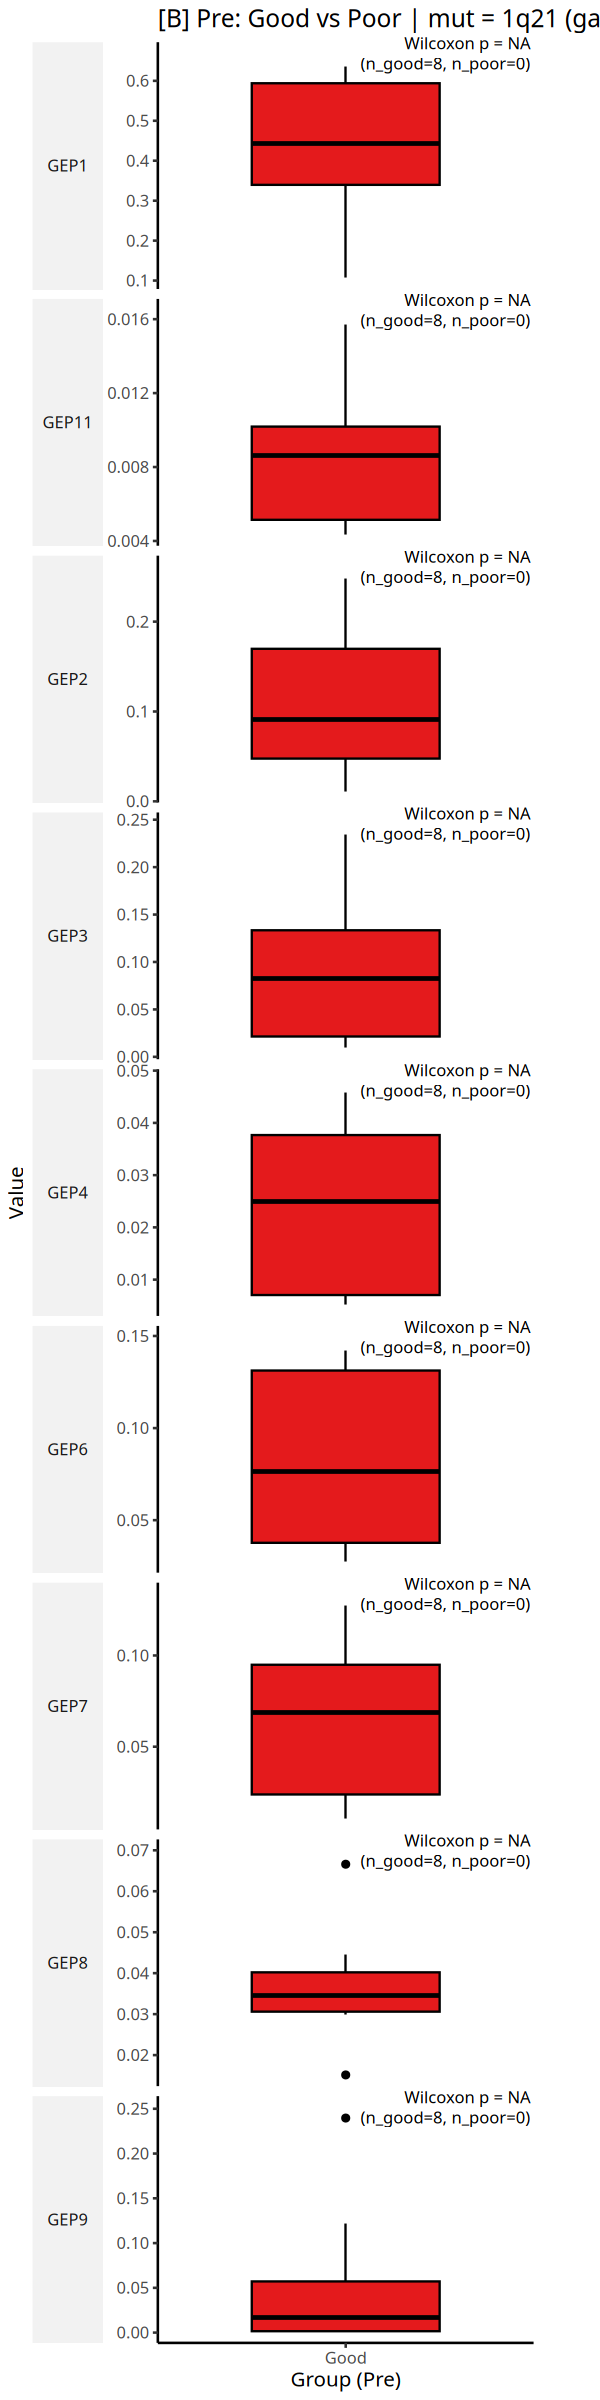

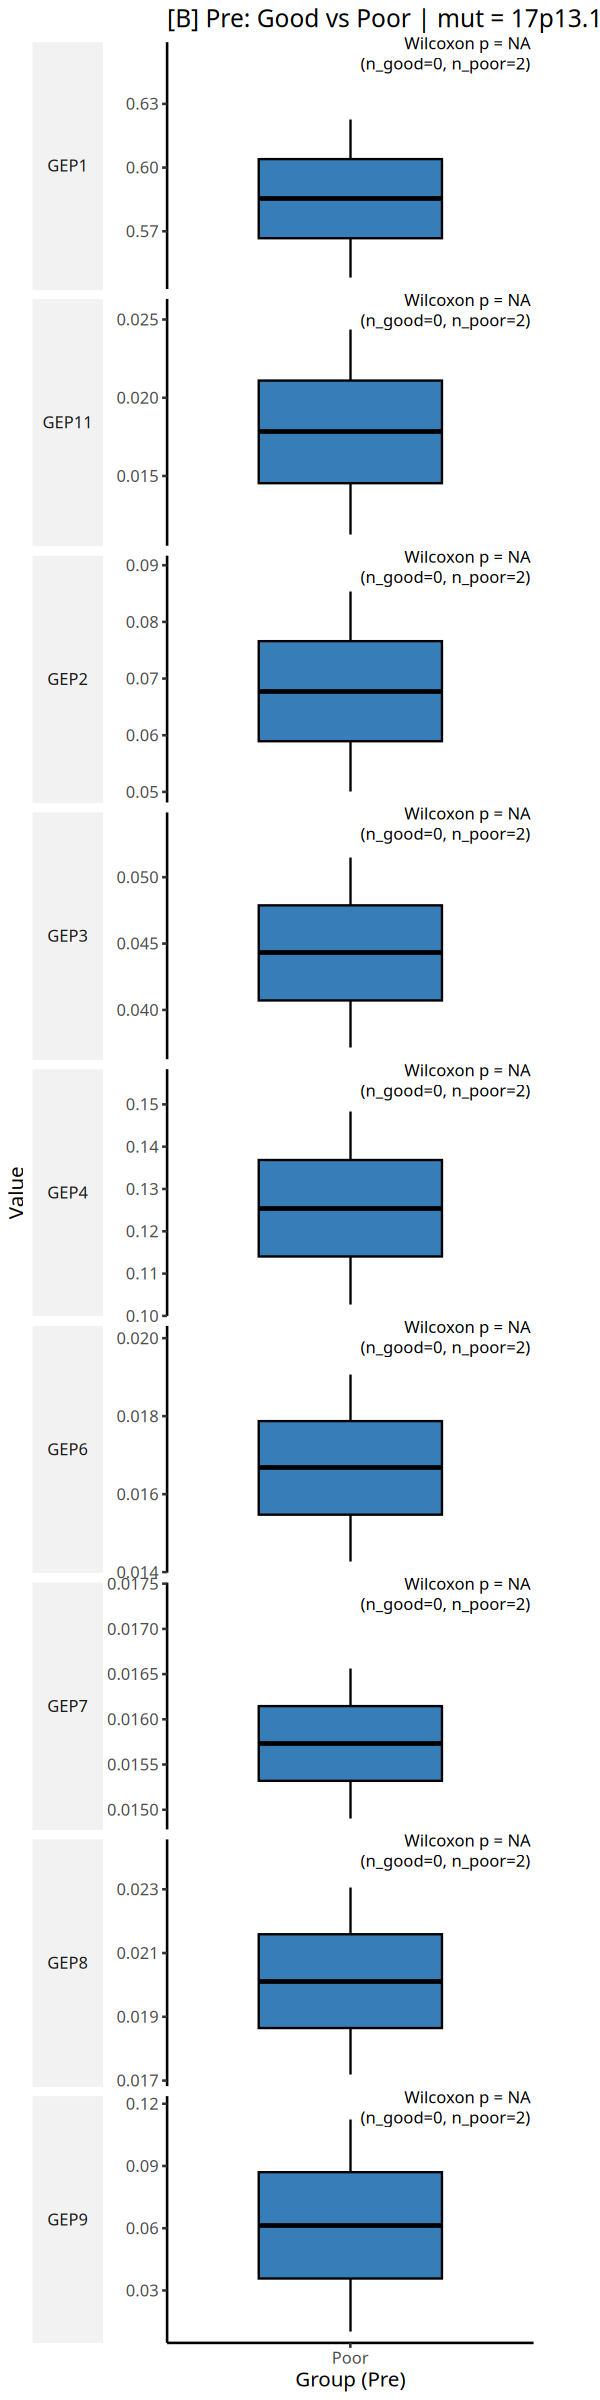

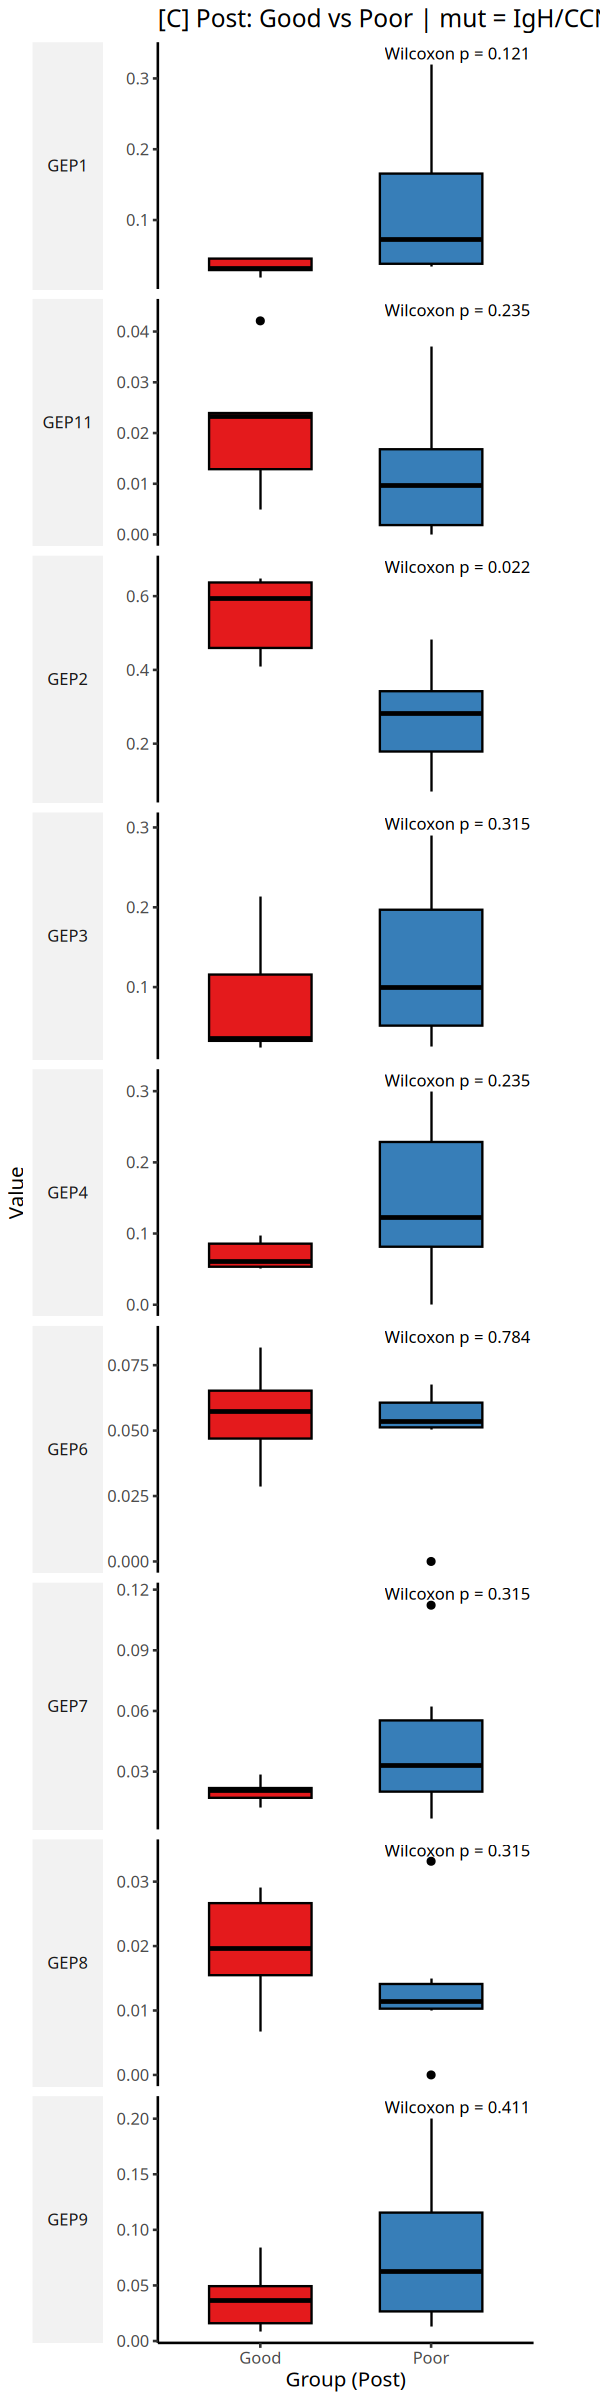

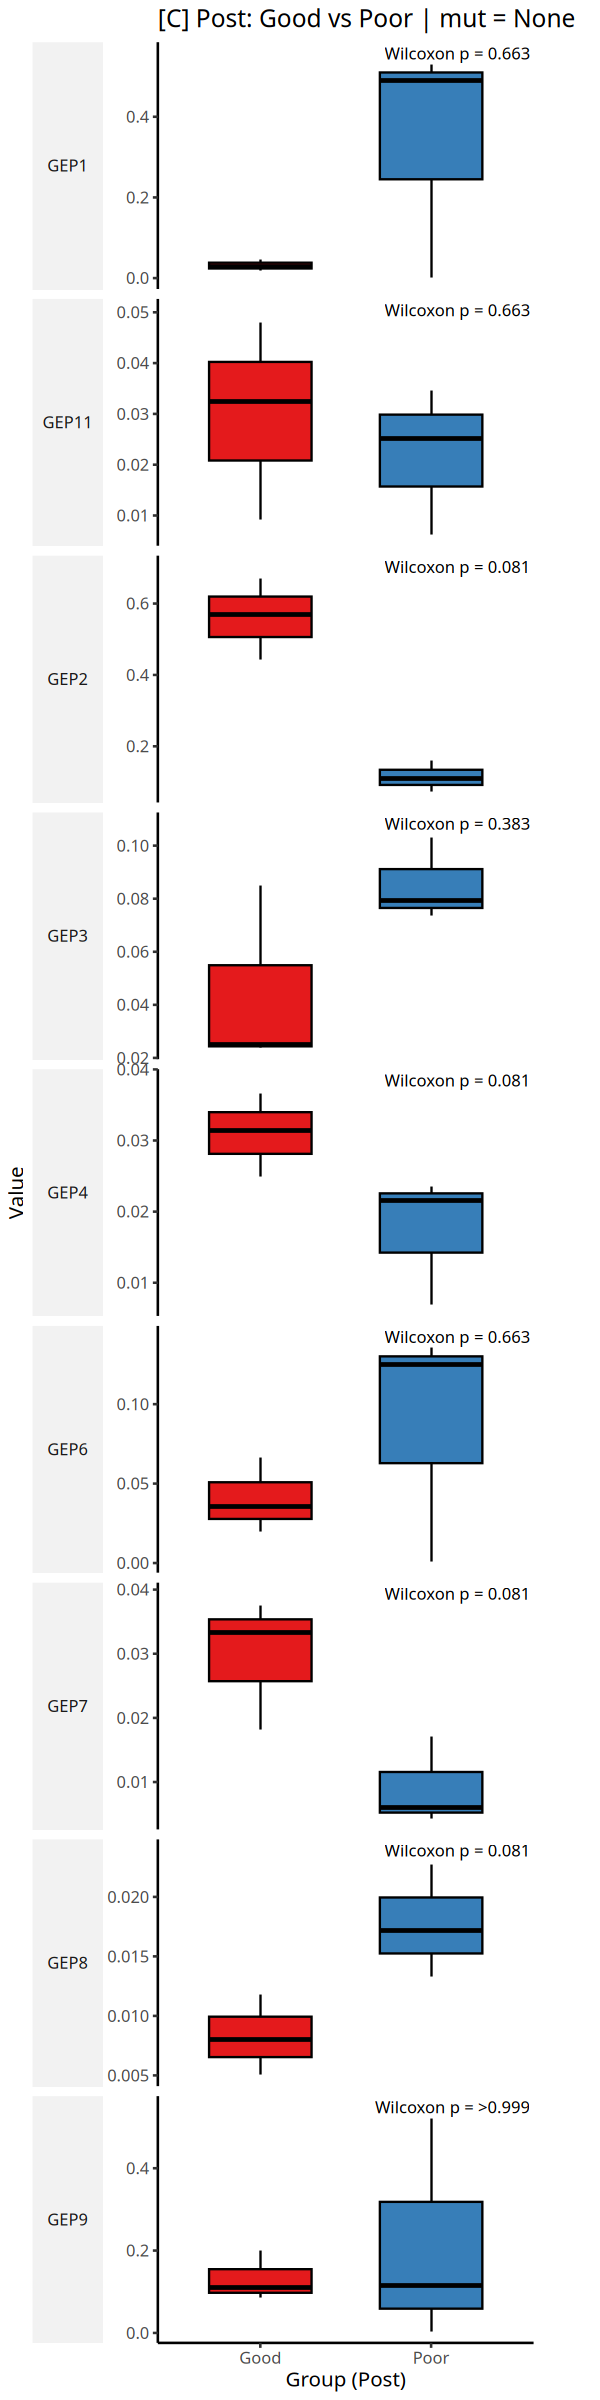

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = -0.60' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = -0.60' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.77' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.77' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 1.00' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 1.00' in 'mbcsToSbcs': dot substituted for <9

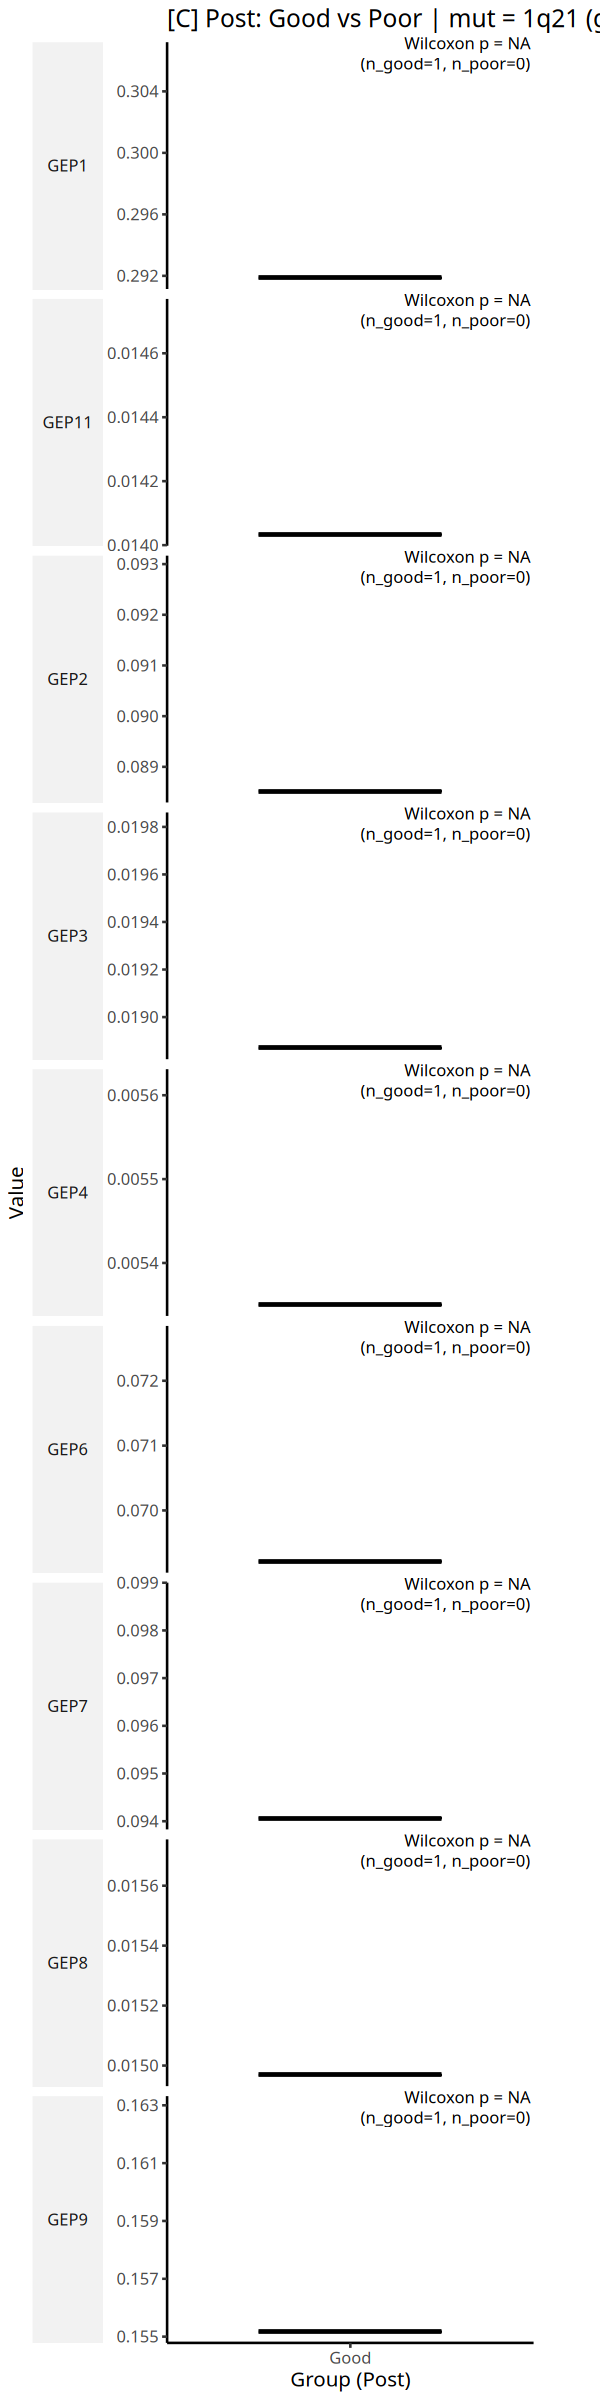

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = -1.00' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = -1.00' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.44' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.44' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.83' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'CliffΔ = 0.83' in 'mbcsToSbcs': dot substituted for <9

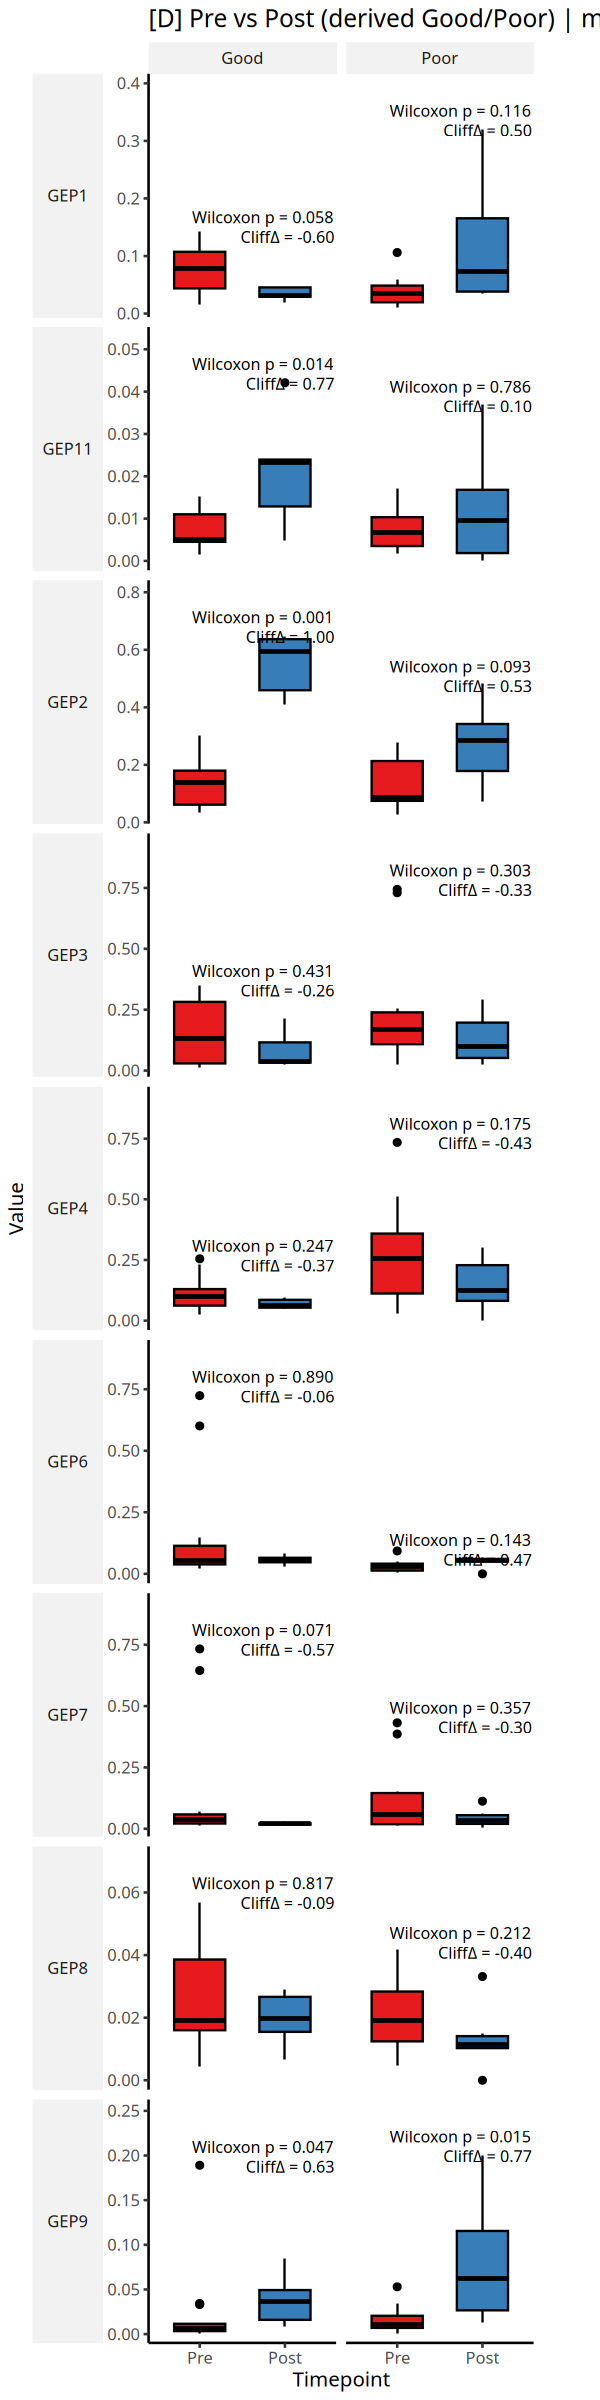

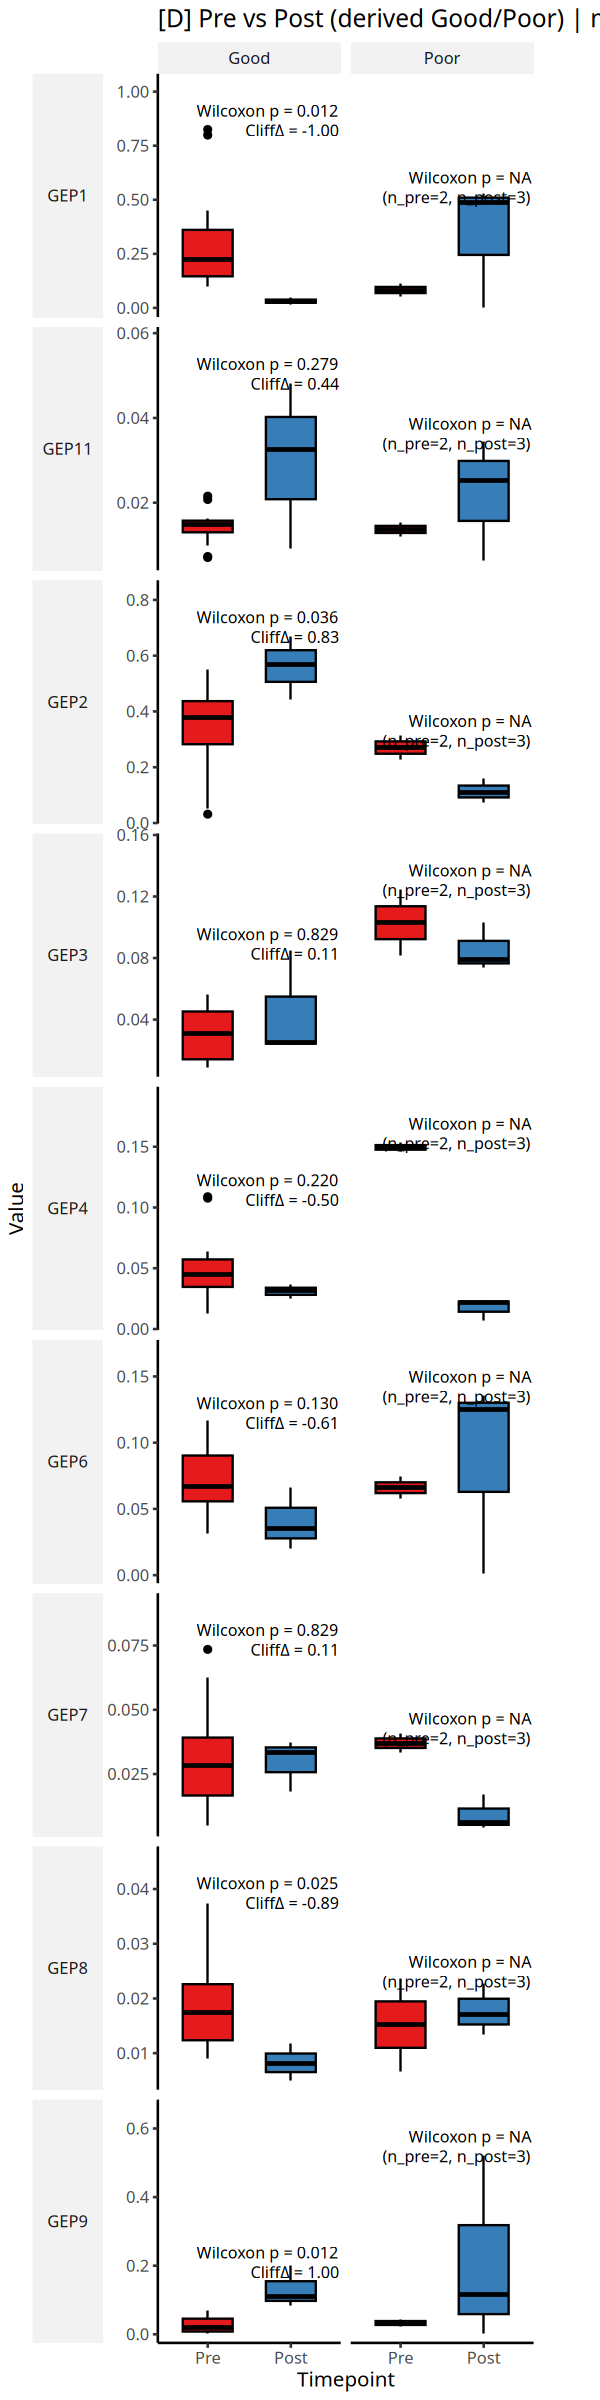

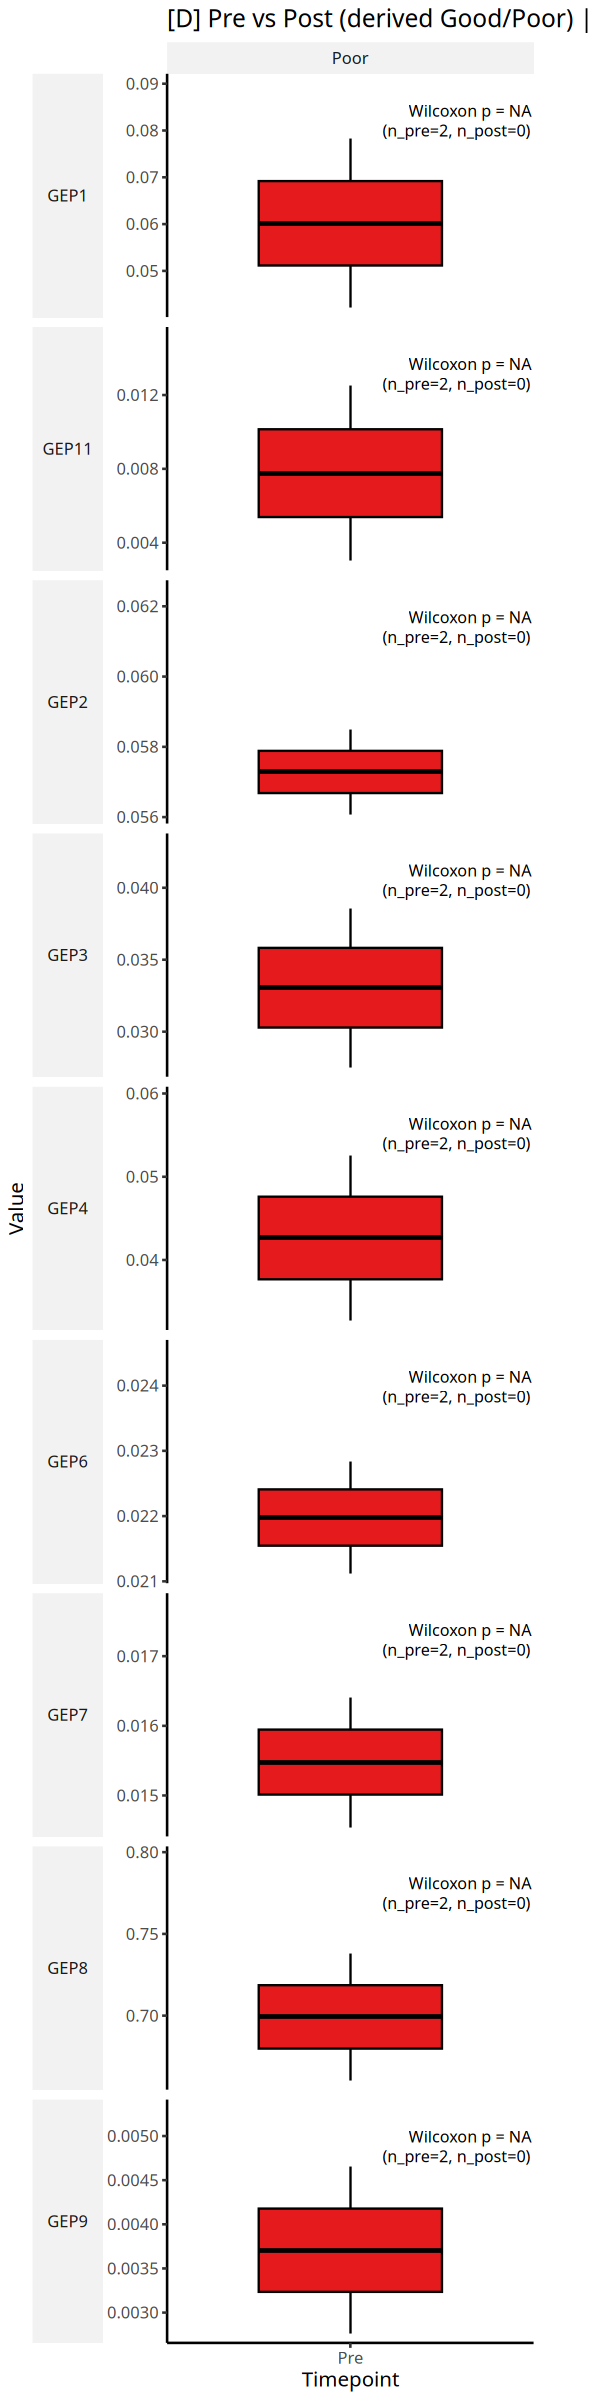

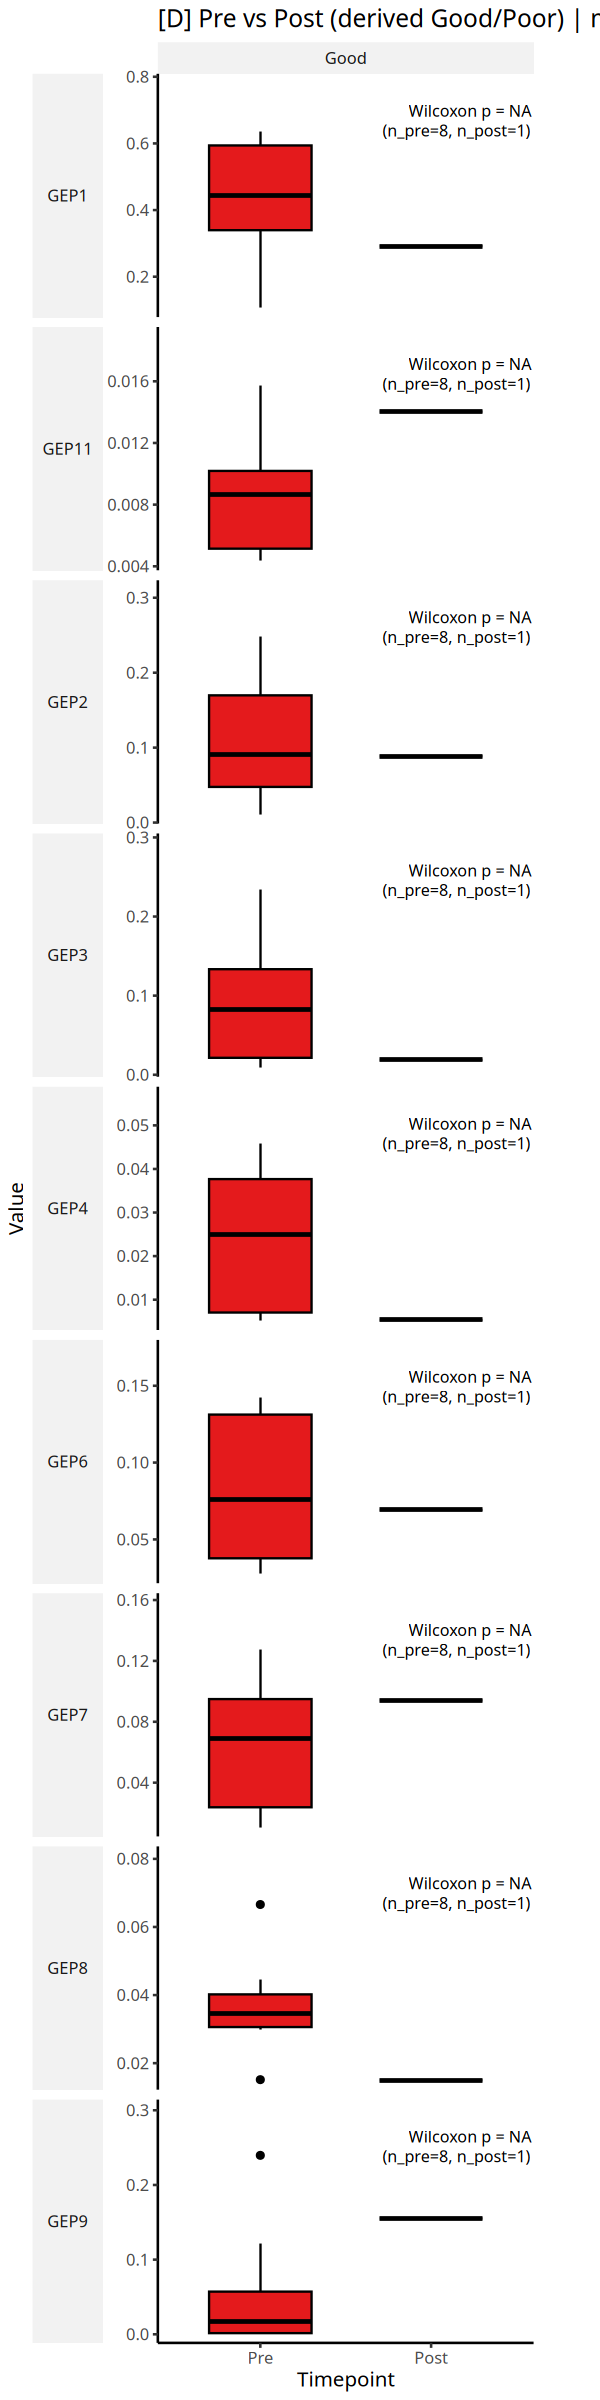

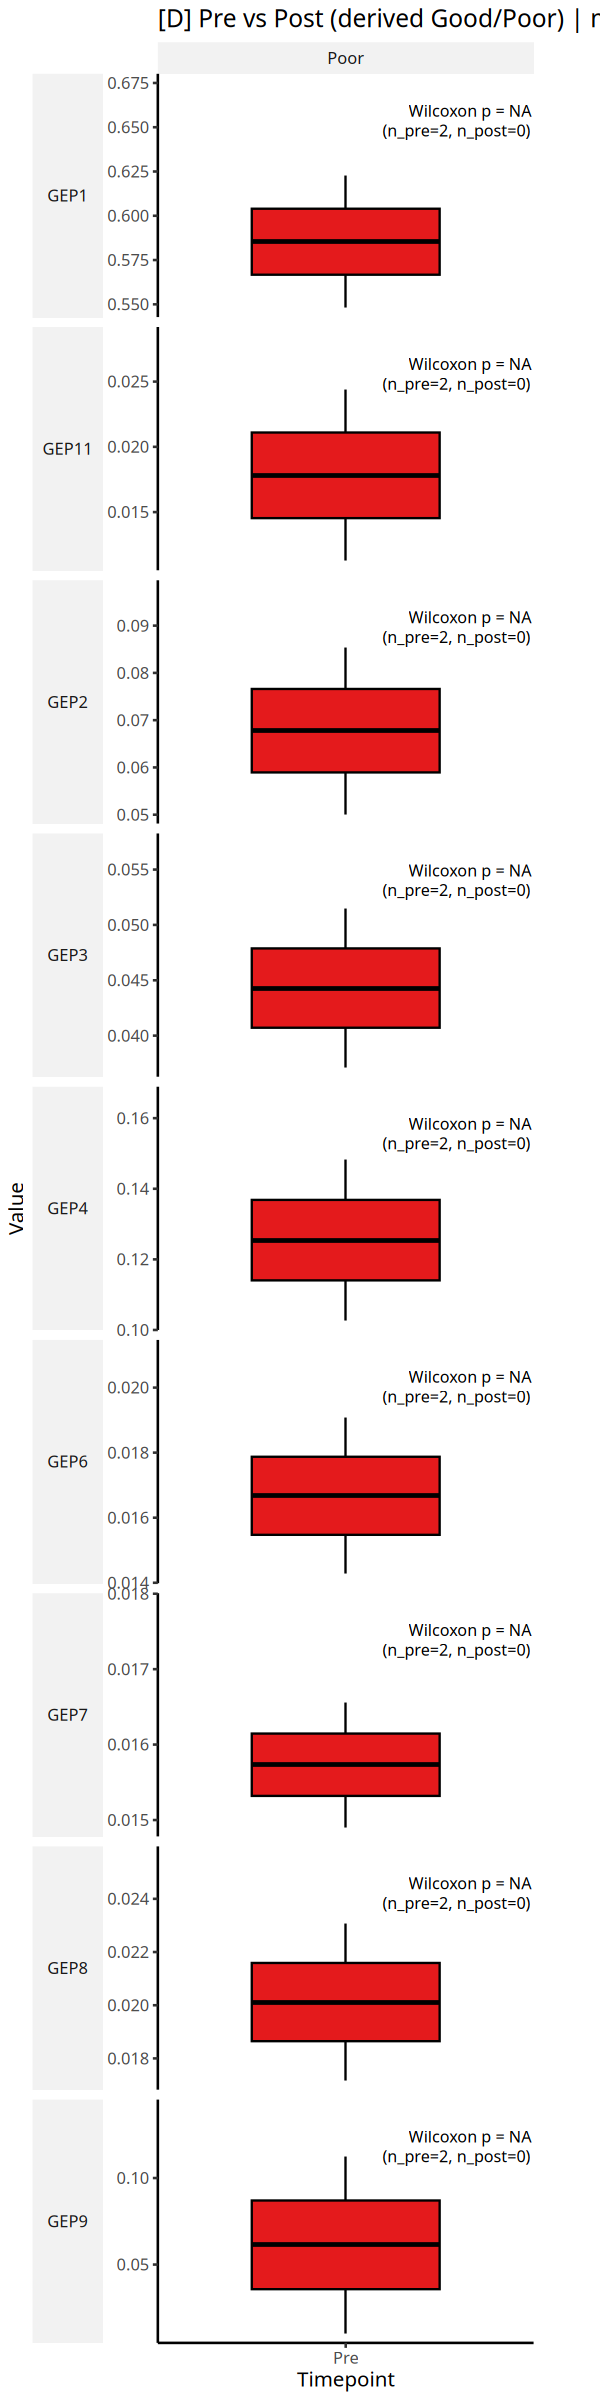

In [51]:
# ============================
# Libraries + settings
# ============================
options(repr.plot.height = 20, repr.plot.width = 5)

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggpubr)
  library(RColorBrewer)
  library(purrr)
  library(broom)
  library(scales)
  library(effsize)
})

usage_feats <- c('GEP1','GEP11','GEP2','GEP3','GEP4','GEP6','GEP7','GEP8','GEP9')

# ---------- Cliff's Δ helpers (silent warnings) ----------
cliffs_delta_manual <- function(x, y) {
  x <- x[is.finite(x)]; y <- y[is.finite(y)]
  nx <- length(x); ny <- length(y)
  if (nx == 0 || ny == 0) return(NA_real_)
  s <- sum(sign(outer(x, y, "-")))
  s / (nx * ny)
}

safe_cliff_delta <- function(post, pre) {
  post <- post[is.finite(post)]
  pre  <- pre[is.finite(pre)]
  if (length(post) == 0 || length(pre) == 0) return(NA_real_)
  est <- suppressWarnings(
    tryCatch(unname(effsize::cliff.delta(post, pre, na.rm = TRUE)$estimate),
             error = function(e) NA_real_)
  )
  if (is.na(est)) cliffs_delta_manual(post, pre) else est
}

# ============================
# Build long table with derived response grouping (Good/Poor) + timepoint
# ============================
make_long_gp <- function(df, feats_to_plot) {
  stopifnot("response" %in% colnames(df))

  df %>%
    mutate(
      response = factor(
        response,
        levels = c("CR_pre","CR_post","VGPR_pre","VGPR_post","PR_pre","PR_post","NR/SD_pre","NR/SD_post")
      )
    ) %>%
    pivot_longer(all_of(feats_to_plot), names_to = "feature", values_to = "value") %>%
    mutate(
      feature        = factor(feature, levels = feats_to_plot),
      timepoint      = ifelse(grepl("pre$", as.character(response), ignore.case = TRUE), "Pre", "Post"),
      response_group = sub("_(pre|post)$", "", as.character(response), ignore.case = TRUE),
      response_group = factor(response_group, levels = c("CR","VGPR","PR","NR/SD")),
      group2         = case_when(
        response_group %in% c("CR","VGPR")   ~ "Good",
        response_group %in% c("PR","NR/SD")  ~ "Poor",
        TRUE ~ NA_character_
      ),
      timepoint = factor(timepoint, levels = c("Pre","Post")),
      group2    = factor(group2, levels = c("Good","Poor"))
    ) %>%
    filter(!is.na(group2))
}

# ============================
# Plot B: Pre only, Good vs Poor (per mut)
# - stats shown as p if powered, else p=NA + n counts
# ============================
plotB_one_mut <- function(df_long_gp, mut_label, min_n_per_group = 3) {
  pre_long <- df_long_gp %>% filter(timepoint == "Pre")
  if (nrow(pre_long) == 0) return(NULL)

  # counts per feature x group2
  cnt <- pre_long %>%
    filter(!is.na(value)) %>%
    count(feature, group2, name = "n") %>%
    tidyr::complete(feature, group2 = c("Good","Poor"), fill = list(n = 0)) %>%
    group_by(feature) %>%
    summarise(
      n_good = n[group2 == "Good"][1],
      n_poor = n[group2 == "Poor"][1],
      ok = (n_good >= min_n_per_group) & (n_poor >= min_n_per_group),
      .groups = "drop"
    )

  row_max <- pre_long %>%
    group_by(feature) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- pre_long %>%
    left_join(cnt, by = "feature") %>%
    group_by(feature) %>%
    summarise(
      ok = first(ok),
      n_good = first(n_good),
      n_poor = first(n_poor),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ group2, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = "feature") %>%
    mutate(
      label = ifelse(
        ok,
        paste0("Wilcoxon p = ", scales::pvalue(p)),
        paste0("Wilcoxon p = NA\n(n_good=", n_good, ", n_poor=", n_poor, ")")
      )
    )

  ggboxplot(pre_long, x = "group2", y = "value", fill = "group2", width = 0.6) +
    scale_fill_manual(values = c("Good" = "#E41A1C", "Poor" = "#377EB8")) +
    facet_grid(feature ~ ., scales = "free_y", switch = "y") +
    labs(x = "Group (Pre)", y = "Value",
         title = paste0("[B] Pre: Good vs Poor | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5)
    ) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE, hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.4
    )
}

# ============================
# Plot C: Post only, Good vs Poor (per mut)
# ============================
plotC_one_mut <- function(df_long_gp, mut_label, min_n_per_group = 3) {
  post_long <- df_long_gp %>% filter(timepoint == "Post")
  if (nrow(post_long) == 0) return(NULL)

  cnt <- post_long %>%
    filter(!is.na(value)) %>%
    count(feature, group2, name = "n") %>%
    tidyr::complete(feature, group2 = c("Good","Poor"), fill = list(n = 0)) %>%
    group_by(feature) %>%
    summarise(
      n_good = n[group2 == "Good"][1],
      n_poor = n[group2 == "Poor"][1],
      ok = (n_good >= min_n_per_group) & (n_poor >= min_n_per_group),
      .groups = "drop"
    )

  row_max <- post_long %>%
    group_by(feature) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- post_long %>%
    left_join(cnt, by = "feature") %>%
    group_by(feature) %>%
    summarise(
      ok = first(ok),
      n_good = first(n_good),
      n_poor = first(n_poor),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ group2, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = "feature") %>%
    mutate(
      label = ifelse(
        ok,
        paste0("Wilcoxon p = ", scales::pvalue(p)),
        paste0("Wilcoxon p = NA\n(n_good=", n_good, ", n_poor=", n_poor, ")")
      )
    )

  ggboxplot(post_long, x = "group2", y = "value", fill = "group2", width = 0.6) +
    scale_fill_manual(values = c("Good" = "#E41A1C", "Poor" = "#377EB8")) +
    facet_grid(feature ~ ., scales = "free_y", switch = "y") +
    labs(x = "Group (Post)", y = "Value",
         title = paste0("[C] Post: Good vs Poor | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5)
    ) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE, hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.4
    )
}

# ============================
# Plot D: Pre vs Post within derived Good/Poor (per mut)
# - ALWAYS plots if any rows exist
# - Wilcoxon only when powered
# - Cliff’s Δ shown only when non-NA
# ============================
plotD_one_mut <- function(df_long_gp, mut_label, min_n_per_timepoint = 3) {
  if (nrow(df_long_gp) == 0) return(NULL)

  cnt <- df_long_gp %>%
    filter(!is.na(value)) %>%
    count(feature, group2, timepoint, name = "n") %>%
    tidyr::complete(feature, group2, timepoint = c("Pre","Post"), fill = list(n = 0)) %>%
    group_by(feature, group2) %>%
    summarise(
      n_pre  = n[timepoint == "Pre"][1],
      n_post = n[timepoint == "Post"][1],
      ok = (n_pre >= min_n_per_timepoint) & (n_post >= min_n_per_timepoint),
      .groups = "drop"
    )

  row_max <- df_long_gp %>%
    group_by(feature, group2) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- df_long_gp %>%
    left_join(cnt, by = c("feature","group2")) %>%
    group_by(feature, group2) %>%
    summarise(
      ok = first(ok),
      n_pre  = first(n_pre),
      n_post = first(n_post),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ timepoint, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      cliffs_delta = if (isTRUE(first(ok))) {
        tryCatch({
          pre  <- value[timepoint == "Pre"]
          post <- value[timepoint == "Post"]
          safe_cliff_delta(post, pre)
        }, error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = c("feature","group2")) %>%
    mutate(
      label = ifelse(
        ok,
        paste0(
          "Wilcoxon p = ", ifelse(is.na(p), "NA", scales::pvalue(p)),
          ifelse(is.na(cliffs_delta), "", paste0("\nCliff\u0394 = ", scales::number(cliffs_delta, accuracy = 0.01)))
        ),
        paste0("Wilcoxon p = NA\n(n_pre=", n_pre, ", n_post=", n_post, ")")
      )
    )

  ggboxplot(df_long_gp, x = "timepoint", y = "value", fill = "timepoint", width = 0.6) +
    scale_fill_brewer(palette = "Set1", drop = FALSE) +
    facet_grid(feature ~ group2, scales = "free_y", switch = "y") +
    labs(x = "Timepoint", y = "Value",
         title = paste0("[D] Pre vs Post (derived Good/Poor) | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      axis.text.x = element_text(angle = 0, hjust = 0.5),
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5),
      panel.spacing = unit(6, "pt")
    ) +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.25))) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE,
      hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.3
    )
}

# ============================
# Loops: for each mut subgroup (response grouping derived from response)
# ============================
stopifnot("mut" %in% colnames(boxplot), "response" %in% colnames(boxplot))
mut_levels <- unique(as.character(boxplot$mut))

# ---- Plot B loop (Pre: Good vs Poor) ----
purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pB <- plotB_one_mut(df_long_gp, mut_label = m, min_n_per_group = 3)
  if (!is.null(pB)) print(pB)
})

# ---- Plot C loop (Post: Good vs Poor) ----
purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pC <- plotC_one_mut(df_long_gp, mut_label = m, min_n_per_group = 3)
  if (!is.null(pC)) print(pC)
})

# ---- Plot D loop (Pre vs Post within derived Good/Poor; CliffΔ only if available) ----
# If you want D smaller:
# options(repr.plot.height = 10, repr.plot.width = 4)

purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pD <- plotD_one_mut(df_long_gp, mut_label = m, min_n_per_timepoint = 3)
  if (!is.null(pD)) print(pD)
})


## 11. Export subgroup comparison figures

Save the B/C/D comparisons for the seven-program subset GEP1, GEP11, GEP2, GEP4, GEP6, GEP8, and GEP9, with one PDF per cytogenetic subgroup and comparison in `usage_plots_by_mut/`. The effect-size helper falls back to a manual Cliff's delta calculation if the package estimator fails.


In [53]:
# ============================
# Libraries + settings
# ============================
options(repr.plot.height = 20, repr.plot.width = 5)

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggpubr)
  library(RColorBrewer)
  library(purrr)
  library(broom)
  library(scales)
  library(effsize)
})

usage_feats <- c('GEP1','GEP11','GEP2','GEP4','GEP6','GEP8','GEP9')

# ---------- Cliff's Δ helpers (silent warnings) ----------
cliffs_delta_manual <- function(x, y) {
  x <- x[is.finite(x)]; y <- y[is.finite(y)]
  nx <- length(x); ny <- length(y)
  if (nx == 0 || ny == 0) return(NA_real_)
  s <- sum(sign(outer(x, y, "-")))
  s / (nx * ny)
}

safe_cliff_delta <- function(post, pre) {
  post <- post[is.finite(post)]
  pre  <- pre[is.finite(pre)]
  if (length(post) == 0 || length(pre) == 0) return(NA_real_)
  est <- suppressWarnings(
    tryCatch(unname(effsize::cliff.delta(post, pre, na.rm = TRUE)$estimate),
             error = function(e) NA_real_)
  )
  if (is.na(est)) cliffs_delta_manual(post, pre) else est
}

# ============================
# Build long table with derived response grouping (Good/Poor) + timepoint
# ============================
make_long_gp <- function(df, feats_to_plot) {
  stopifnot("response" %in% colnames(df))

  df %>%
    mutate(
      response = factor(
        response,
        levels = c("CR_pre","CR_post","VGPR_pre","VGPR_post","PR_pre","PR_post","NR/SD_pre","NR/SD_post")
      )
    ) %>%
    pivot_longer(all_of(feats_to_plot), names_to = "feature", values_to = "value") %>%
    mutate(
      feature        = factor(feature, levels = feats_to_plot),
      timepoint      = ifelse(grepl("pre$", as.character(response), ignore.case = TRUE), "Pre", "Post"),
      response_group = sub("_(pre|post)$", "", as.character(response), ignore.case = TRUE),
      response_group = factor(response_group, levels = c("CR","VGPR","PR","NR/SD")),
      group2         = case_when(
        response_group %in% c("CR","VGPR")   ~ "Good",
        response_group %in% c("PR","NR/SD")  ~ "Poor",
        TRUE ~ NA_character_
      ),
      timepoint = factor(timepoint, levels = c("Pre","Post")),
      group2    = factor(group2, levels = c("Good","Poor"))
    ) %>%
    filter(!is.na(group2))
}

# ============================
# Plot B: Pre only, Good vs Poor (per mut)
# ============================
plotB_one_mut <- function(df_long_gp, mut_label, min_n_per_group = 3) {
  pre_long <- df_long_gp %>% filter(timepoint == "Pre")
  if (nrow(pre_long) == 0) return(NULL)

  cnt <- pre_long %>%
    filter(!is.na(value)) %>%
    count(feature, group2, name = "n") %>%
    tidyr::complete(feature, group2 = c("Good","Poor"), fill = list(n = 0)) %>%
    group_by(feature) %>%
    summarise(
      n_good = n[group2 == "Good"][1],
      n_poor = n[group2 == "Poor"][1],
      ok = (n_good >= min_n_per_group) & (n_poor >= min_n_per_group),
      .groups = "drop"
    )

  row_max <- pre_long %>%
    group_by(feature) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- pre_long %>%
    left_join(cnt, by = "feature") %>%
    group_by(feature) %>%
    summarise(
      ok = first(ok),
      n_good = first(n_good),
      n_poor = first(n_poor),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ group2, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = "feature") %>%
    mutate(
      label = ifelse(
        ok,
        paste0("Wilcoxon p = ", scales::pvalue(p)),
        paste0("Wilcoxon p = NA\n(n_good=", n_good, ", n_poor=", n_poor, ")")
      )
    )

  ggboxplot(pre_long, x = "group2", y = "value", fill = "group2", width = 0.6) +
    scale_fill_manual(values = c("Good" = "#E41A1C", "Poor" = "#377EB8")) +
    facet_grid(feature ~ ., scales = "free_y", switch = "y") +
    labs(x = "Group (Pre)", y = "Value",
         title = paste0("[B] Pre: Good vs Poor | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5)
    ) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE, hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.4
    )
}

# ============================
# Plot C: Post only, Good vs Poor (per mut)
# ============================
plotC_one_mut <- function(df_long_gp, mut_label, min_n_per_group = 3) {
  post_long <- df_long_gp %>% filter(timepoint == "Post")
  if (nrow(post_long) == 0) return(NULL)

  cnt <- post_long %>%
    filter(!is.na(value)) %>%
    count(feature, group2, name = "n") %>%
    tidyr::complete(feature, group2 = c("Good","Poor"), fill = list(n = 0)) %>%
    group_by(feature) %>%
    summarise(
      n_good = n[group2 == "Good"][1],
      n_poor = n[group2 == "Poor"][1],
      ok = (n_good >= min_n_per_group) & (n_poor >= min_n_per_group),
      .groups = "drop"
    )

  row_max <- post_long %>%
    group_by(feature) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- post_long %>%
    left_join(cnt, by = "feature") %>%
    group_by(feature) %>%
    summarise(
      ok = first(ok),
      n_good = first(n_good),
      n_poor = first(n_poor),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ group2, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = "feature") %>%
    mutate(
      label = ifelse(
        ok,
        paste0("Wilcoxon p = ", scales::pvalue(p)),
        paste0("Wilcoxon p = NA\n(n_good=", n_good, ", n_poor=", n_poor, ")")
      )
    )

  ggboxplot(post_long, x = "group2", y = "value", fill = "group2", width = 0.6) +
    scale_fill_manual(values = c("Good" = "#E41A1C", "Poor" = "#377EB8")) +
    facet_grid(feature ~ ., scales = "free_y", switch = "y") +
    labs(x = "Group (Post)", y = "Value",
         title = paste0("[C] Post: Good vs Poor | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5)
    ) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE, hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.4
    )
}

# ============================
# Plot D: Pre vs Post within derived Good/Poor (per mut)
# - ALWAYS plots if any rows exist
# - Wilcoxon only when powered
# - Cliff’s Δ shown only when non-NA
# ============================
plotD_one_mut <- function(df_long_gp, mut_label, min_n_per_timepoint = 3) {
  if (nrow(df_long_gp) == 0) return(NULL)

  cnt <- df_long_gp %>%
    filter(!is.na(value)) %>%
    count(feature, group2, timepoint, name = "n") %>%
    tidyr::complete(feature, group2, timepoint = c("Pre","Post"), fill = list(n = 0)) %>%
    group_by(feature, group2) %>%
    summarise(
      n_pre  = n[timepoint == "Pre"][1],
      n_post = n[timepoint == "Post"][1],
      ok = (n_pre >= min_n_per_timepoint) & (n_post >= min_n_per_timepoint),
      .groups = "drop"
    )

  row_max <- df_long_gp %>%
    group_by(feature, group2) %>%
    summarise(ymax = max(value, na.rm = TRUE), .groups = "drop") %>%
    mutate(ypos = ifelse(is.finite(ymax), ymax * 1.05, 1))

  stats <- df_long_gp %>%
    left_join(cnt, by = c("feature","group2")) %>%
    group_by(feature, group2) %>%
    summarise(
      ok = first(ok),
      n_pre  = first(n_pre),
      n_post = first(n_post),
      p = if (isTRUE(first(ok))) {
        tryCatch(broom::glance(wilcox.test(value ~ timepoint, exact = FALSE))$p.value,
                 error = function(e) NA_real_)
      } else NA_real_,
      cliffs_delta = if (isTRUE(first(ok))) {
        tryCatch({
          pre  <- value[timepoint == "Pre"]
          post <- value[timepoint == "Post"]
          safe_cliff_delta(post, pre)
        }, error = function(e) NA_real_)
      } else NA_real_,
      .groups = "drop"
    ) %>%
    left_join(row_max, by = c("feature","group2")) %>%
    mutate(
      label = ifelse(
        ok,
        paste0(
          "Wilcoxon p = ", ifelse(is.na(p), "NA", scales::pvalue(p)),
          ifelse(is.na(cliffs_delta), "", paste0("\nCliff\u0394 = ", scales::number(cliffs_delta, accuracy = 0.01)))
        ),
        paste0("Wilcoxon p = NA\n(n_pre=", n_pre, ", n_post=", n_post, ")")
      )
    )

  ggboxplot(df_long_gp, x = "timepoint", y = "value", fill = "timepoint", width = 0.6) +
    scale_fill_brewer(palette = "Set1", drop = FALSE) +
    facet_grid(feature ~ group2, scales = "free_y", switch = "y") +
    labs(x = "Timepoint", y = "Value",
         title = paste0("[D] Pre vs Post (derived Good/Poor) | mut = ", mut_label)) +
    theme_classic(base_size = 12) +
    theme(
      axis.text.x = element_text(angle = 0, hjust = 0.5),
      legend.position = "none",
      strip.placement = "outside",
      strip.background = element_rect(fill = "grey95", colour = NA),
      strip.text.y.left = element_text(angle = 0, face = "bold"),
      plot.margin = margin(5.5, 40, 5.5, 5.5),
      panel.spacing = unit(6, "pt")
    ) +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.25))) +
    coord_cartesian(clip = "off") +
    geom_text(
      data = stats,
      aes(x = Inf, y = ypos, label = label),
      inherit.aes = FALSE,
      hjust = 1.02, vjust = 0.5, lineheight = 1.05, size = 3.3
    )
}

# ============================================================
# SAVE: one PDF per mut per plot-group into a folder
# ============================================================
stopifnot("mut" %in% colnames(boxplot), "response" %in% colnames(boxplot))

out_dir <- "usage_plots_by_mut"
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)

# Recommended sizes (you can change)
pdf_w_BC <- 5
pdf_h_BC <- 20
pdf_w_D  <- 5
pdf_h_D  <- 20

safe_name <- function(x) gsub("[^A-Za-z0-9_-]+", "_", as.character(x))

mut_levels <- unique(as.character(boxplot$mut))

# ---- Plot B loop: save ----
purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pB <- plotB_one_mut(df_long_gp, mut_label = m, min_n_per_group = 3)
  if (is.null(pB)) return()

  fn <- file.path(out_dir, sprintf("PlotB_Pre_GoodVsPoor_mut_%s.pdf", safe_name(m)))
  ggsave(fn, plot = pB, width = pdf_w_BC, height = pdf_h_BC, units = "in", device = cairo_pdf)
})

# ---- Plot C loop: save ----
purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pC <- plotC_one_mut(df_long_gp, mut_label = m, min_n_per_group = 3)
  if (is.null(pC)) return()

  fn <- file.path(out_dir, sprintf("PlotC_Post_GoodVsPoor_mut_%s.pdf", safe_name(m)))
  ggsave(fn, plot = pC, width = pdf_w_BC, height = pdf_h_BC, units = "in", device = cairo_pdf)
})

# ---- Plot D loop: save ----
purrr::walk(mut_levels, function(m) {
  dfm <- boxplot %>% filter(mut == m)
  feats_to_plot <- intersect(usage_feats, colnames(dfm))
  if (length(feats_to_plot) == 0) return()

  df_long_gp <- make_long_gp(dfm, feats_to_plot)
  pD <- plotD_one_mut(df_long_gp, mut_label = m, min_n_per_timepoint = 3)
  if (is.null(pD)) return()

  fn <- file.path(out_dir, sprintf("PlotD_PreVsPost_DerivedGoodPoor_mut_%s.pdf", safe_name(m)))
  ggsave(fn, plot = pD, width = pdf_w_D, height = pdf_h_D, units = "in", device = cairo_pdf)
})

cat("Done. PDFs saved under: ", normalizePath(out_dir), "\n")


Done. PDFs saved under:  /home/data/arsenal_1118/usage_plots_by_mut 
